# DRVI on the malignant epithelial subset

- DRVI with 64 latent dimensions on the malignant cells called in 03_1 (20 cohorts), trained on the 2,000 batch-aware HVGs of 03_2 without the MT- genes
- Encoder 128, 128 and decoder 128, 128 (02 used 256, 128 and 128, 256), gene-batch dispersion, cohort as batch key, 400 full epochs, seed 123
- No labels key: the latent space is built without any annotation, and the groupings below are only read back afterwards as captions
- After the integration the cells are clustered with Leiden on the DRVI dimensions (resolutions 0.25 - 2.0, 1.5 the one used, clusters under 100 cells merged into their neighbours)
- UMAPs of the latent space, vanished dimensions, interpretability scores, SMI matches and enrichment of the dimensions
- Outputs: model, embedding and the 03_2 object with the latent space, all under DATA_DIR

The OOD and IND interpretability scores, which name a dimension by its genes, are the reading that owes nothing to any annotation.

## Libraries

In [1]:
import os
import sys
import tempfile
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import scvi
import drvi
from drvi.model import DRVI

import warnings
warnings.filterwarnings("ignore")

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Scanpy setting: clean white background and high resolution figures
sc.settings.set_figure_params(dpi=300, facecolor="white")
# Set the level of verbosity of scanpy to get more detailed info
sc.settings.verbosity = 3

# Tell Jupyter to show all outputs and not only the last one
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

!pip list

/home/catt/miniforge3/envs/benchmark-py-r/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Package                 Version     Build
----------------------- ----------- -----
absl-py                 2.5.1
aiohappyeyeballs        2.7.1
aiohttp                 3.14.5
aiosignal               1.4.0
anndata                 0.13.4
anndata2ri              2.0
annotated-types         0.8.0
annoy                   1.17.3
array-api-compat        1.15.0
asttokens               3.0.2
attrs                   26.1.0
bbknn                   1.6.0
cached-property         2.0.1
celltypist              1.7.1
certifi                 2026.10.23
cffi                    2.1.1
charset-normalizer      3.5.2
click                   8.5.0
cloudpickle             3.1.2
comm                    0.2.3
contourpy               1.4.0
cycler                  0.12.1
Cython                  3.3.0
debugpy                 1.8.22
Deprecated              3.0.0
docrep                  0.3.2
donfig                  0.8.1.post1
drvi-py                 0.2.7
et_xmlfile              2.0.0
executing               2.3.0


## Configuration

Run id drvi_tum_64_nomt: paths and constants come from utils/cell_set.py, shared with run_drvi_tum.py.

In [2]:
import os

SEED = 123
N_EPOCHS = 400 # the full run: scvi-tools warms the KL term up over exactly these
EARLY_STOPPING = False # off, see the training section
OVERWRITE = False # False reuses the model / embedding already on disk

PROJECT_DIR = Path.cwd().parents[1] # run from 03_3_drvi_run/
PHASE_DIR = PROJECT_DIR / "03_drvi_tumoral_epi"

# File names and thresholds of the phase, shared with run_drvi_tum.py.
sys.path.insert(0, str(PHASE_DIR / "utils"))
import cell_set as C

C.banner("03_3 DRVI run")

N_LATENT = C.N_LATENT # 64
BATCH_KEY = C.BATCH_KEY # 'cohort'
LABEL_KEY = C.LABEL_KEY # 'cell_type': the post-CNV label, constant 'malignant'
LEIDEN_KEY = C.LEIDEN_KEY # 'drvi_leiden': Leiden on the live DRs at resolution 1.5, made below

RUN_ID = C.run_id() # drvi_tum_64_nomt

DATA_DIR = C.data_dir()
TUM_DIR = C.tum_dir() # $DATA_DIR/03_tum

# Input: the 2,000 HVGs without the MT- genes (03_2 reduce_data_tum.py), raw counts in .layers.
INPUT_H5AD = C.hvg_path(".h5ad")
# The definitive object of 03_2 (all genes, scran log-norm): read at the end, to carry the
# latent space and the Leiden columns over for the steps after.
FULL_H5AD = C.path(".h5ad")

# Outputs, all under DATA_DIRS
MODEL_PATH = TUM_DIR / f"model_{RUN_ID}.pt" # one flat file (see save_model)
LATENT_H5AD = TUM_DIR / f"embed_{RUN_ID}.h5ad" # latent space + interpretability scores
DOWNSTREAM_H5AD = C.path(f"_{RUN_ID}.h5ad") # the 03_2 object + obsm['X_drvi']

print(f"run id      {RUN_ID}")
print(f"input       {INPUT_H5AD}")
print(f"model       {MODEL_PATH}")
print(f"latent      {LATENT_H5AD}")
print(f"downstream  {DOWNSTREAM_H5AD}")

03_3 DRVI run  |  run drvi_tum_64_nomt
DATA_DIR : /home/catt/QCB-thesis-final/datasets

run id      drvi_tum_64_nomt
input       /home/catt/QCB-thesis-final/datasets/03_tum/shiao_tum_hvg_2k_nomt.h5ad
model       /home/catt/QCB-thesis-final/datasets/03_tum/model_drvi_tum_64_nomt.pt
latent      /home/catt/QCB-thesis-final/datasets/03_tum/embed_drvi_tum_64_nomt.h5ad
downstream  /home/catt/QCB-thesis-final/datasets/03_tum/shiao_tum_drvi_tum_64_nomt.h5ad


### Figures and tables

In [3]:
FIG_DIR = PHASE_DIR / "figures" / f"03_3_{RUN_ID}"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sc.settings.figdir = FIG_DIR

TABLE_DIR = PHASE_DIR / "tables" / f"03_3_{RUN_ID}"
TABLE_DIR.mkdir(parents=True, exist_ok=True)


def savefig(name, fig=None, dpi=300):
    """Save a matplotlib figure (the current one by default) into FIG_DIR.

    For the DRVI and seaborn plots, which draw on the pyplot state instead of going through
    sc.pl and so ignore sc.settings.figdir. The run id is appended to the name, so figures
    from different latent sizes stay distinguishable even once they are pulled out of their
    folder.
    """
    fig = plt.gcf() if fig is None else fig
    path = FIG_DIR / f"{name}_{RUN_ID}.png"
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"[fig] {path}")
    return path


print(f"figures     {FIG_DIR}")
print(f"tables      {TABLE_DIR}")

figures     /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/figures/03_3_drvi_tum_64_nomt
tables      /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/tables/03_3_drvi_tum_64_nomt


In [4]:
print("Last run with scvi-tools version:", scvi.__version__)
print("Last run with DRVI version:", drvi.__version__)

Last run with scvi-tools version: 1.5.1
Last run with DRVI version: 0.2.7


### Model I/O


In [5]:
def save_model(model, path):
    """Save a DRVI model as the single file `path`.

    model.save() writes `<dir>/model.pt` and gives no say over the file name, so it writes
    into a scratch directory *inside the destination folder* (same filesystem, so the move
    below is a rename and not a copy) and the one file it produced is then renamed.
    """
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(dir=path.parent) as scratch:
        model.save(scratch, overwrite=True)
        Path(scratch, "model.pt").replace(path)
    return path


def load_model(path, adata):
    """Load a DRVI model from the single file `path`; the counterpart of save_model.

    DRVI.load() insists on a directory containing `model.pt`, so it gets a scratch one
    holding a symlink to the real file: nothing is copied, and the scratch is gone by the
    time this returns.
    """
    path = Path(path).resolve()
    with tempfile.TemporaryDirectory(dir=path.parent) as scratch:
        os.symlink(path, Path(scratch, "model.pt"))
        return DRVI.load(scratch, adata)

## Load dataset

In [6]:
adata = sc.read_h5ad(INPUT_H5AD)
adata

print(f"{adata.n_obs:,} cells x {adata.n_vars:,} HVGs")
print("First 10 HVG genes:", list(adata.var_names[:10]))

# Sanity checks on what 03_2 produced: the right cell set and the counts layer present.
assert adata.obs[C.COMPARTMENT_KEY].astype(str).nunique() == 1, "not a single-compartment object"
assert adata.obs[C.COMPARTMENT_KEY].astype(str).iloc[0] == C.compartment(), \
    f"compartment is not {C.compartment()!r}: this is not the malignant object"
assert "counts" in adata.layers, "raw counts layer missing, DRVI has nothing to train on"
# No cell without a CNV call can be here.
assert (adata.obs[C.STATUS_KEY].astype(str) != "not_tested").all(), \
    "not_tested cells in the input: 03_2 should have dropped them"

print("compartment :", adata.obs[C.COMPARTMENT_KEY].astype(str).unique().tolist())
print("cnv_status  :", sorted(adata.obs[C.STATUS_KEY].astype(str).unique().tolist()))
print("cell_type   :", sorted(adata.obs[LABEL_KEY].astype(str).unique().tolist()))
print(f"{adata.obs[BATCH_KEY].nunique()} cohorts")

adata.obs[BATCH_KEY].value_counts()

AnnData object with n_obs × n_vars = 41943 × 2000
    obs: 'sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'cell_type', 'celltypist_predicted', 'cnv_status', 'cnv_score', 'cnv_corr', 'cell_type_01_4', 'celltypist_predicted_cnv', 'compartment', 'size_factors', 'S_score', 'G2M_score', 'phase'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable'
    uns: 'cell_type_01_4_colors', 'cohort_colors', 'hvg_panel', 'hvg_panel_added', 'hvg_panel_dropped', 'log1p', 'neighbors', 'pca', 'phase_colors', 'umap'
    obsm: 'X_

41,943 cells x 2,000 HVGs
First 10 HVG genes: ['LTF', 'UBE2C', 'PTTG1', 'CDC20', 'CDK1', 'CCNB1', 'BIRC5', 'CXCL10', 'SPP1', 'RNASE1']
compartment : ['tum']
cnv_status  : ['malignant']
cell_type   : ['malignant']
20 cohorts


cohort
Patient16    7684
Patient56    5997
Patient26    4826
Patient53    3659
Patient43    2826
Patient47    2701
Patient17    2386
Patient63    2297
Patient46    2218
Patient45    2106
Patient11    1116
Patient19     919
Patient18     746
Patient48     472
Patient09     471
Patient64     455
Patient01     369
Patient42     278
Patient20     218
Patient10     199
Name: count, dtype: int64

## Setup the model
- Seed fixed for reproducibility
- cohort as the batch to correct, as in phase 02 and in the 03_2 reduction
- n_latent = 64
- no labels_key as it is "malignant" for each cell
- Encoder / decoder dims [128, 128] / [128, 128]
- dispersion='gene-batch': really important parameter for this TNBC dataset, and the
  reason 03_2 keeps MIN_CELLS_PER_COHORT = 100 - a dispersion column per gene
  *and* per batch cannot be fitted on a small cohort.

In [7]:
# Setup the anndata for scvi-tools
DRVI.setup_anndata(
    adata,
    layer="counts",       # raw unnormalised data (used by default)
    batch_key=BATCH_KEY,  # the batch to fix
    # labels_key is left None on purpose: DRVI is unsupervised here, no annotation enters
    # the latent space.
)

# Setting seed
scvi.settings.seed = SEED

# Setup the model
model = DRVI(
    adata,
    n_latent=N_LATENT,
    encoder_dims=[128, 128],
    decoder_dims=[128, 128],
    dispersion="gene-batch",   # really important parameter for TNBC
)

model

Seed set to 123


INFO     DRVI: The model has been initialized                                                                      


DRVI 
Latent size: 64, splits: 64, pooling of splits: 'logsumexp', 
Encoder dims: [128, 128], 
Decoder dims: [128, 128], 
Gene likelihood: pnb, 

Training status: Not Trained

## Train the model
- N_EPOCHS (400) full epochs, as in the DRVI tutorial
- No early stopping (EARLY_STOPPING = False)
- Train / validation split is the scvi-tools default, 0.9 / 0.1

On the cluster the identical run is submit_drvi_tum.slurm, which calls run_drvi_tum.py with the same
defaults; the model it writes loads back into the cell below.

In [8]:
# Train only if the model is not on disk yet, or if OVERWRITE asks for a retrain.
# The training uses the GPU if one is available, otherwise the CPU.
if OVERWRITE or not MODEL_PATH.exists():
    model.train(
        max_epochs=N_EPOCHS,
        early_stopping=EARLY_STOPPING,   # False: the KL warmup needs all N_EPOCHS
        early_stopping_patience=50,      # only read when EARLY_STOPPING is True
    )
    save_model(model, MODEL_PATH)
    print(f"[model] saved to {MODEL_PATH}")
else:
    print(f"[model] {MODEL_PATH} already exists, not retraining (OVERWRITE=False)")

[model] /home/catt/QCB-thesis-final/datasets/03_tum/model_drvi_tum_64_nomt.pt already exists, not retraining (OVERWRITE=False)


## Latent space + Graph + UMAP + PCA on latent space

In [9]:
# Load the model back, so the cells below can be re-run without retraining
model = load_model(MODEL_PATH, adata)
model

INFO     File /home/catt/QCB-thesis-final/datasets/03_tum/tmp28wxp4ij/model.pt already downloaded                  
INFO     DRVI: The model is trained with DRVI version 0.2.7.                                                       
INFO     DRVI: Updaging data setup config ...                                                                      
INFO     DRVI: Done updating data source registry. Loading in DRVI version 0.2.7.                                  
INFO     DRVI: Loading model from DRVI version 0.2.7.                                                              
INFO     DRVI: Done updating model args. Loading in 0.2.7.                                                         
INFO     DRVI: The model has been initialized                                                                      


DRVI 
Latent size: 64, splits: 64, pooling of splits: 'logsumexp', 
Encoder dims: [128, 128], 
Decoder dims: [128, 128], 
Gene likelihood: pnb, 

Training status: Trained

In [10]:
# The DRVI-specific view of the run: the latent space as .X, one var per latent dimension
# carrying its stats and interpretability scores.
if OVERWRITE or not LATENT_H5AD.exists():
    embed = ad.AnnData(model.get_latent_representation(), obs=adata.obs)

    # We set latent dimension statistics
    print("Setting latent dimension stats ...")
    model.set_latent_dimension_stats(embed, vanished_threshold=0.5)

    # We immediately calculate the interpretability gene scores with different approaches
    print("Calculating gene scores per factor ...")
    # out-of-distribution (OOD) approach uses decoder reconstructions to calculate gene scores (faster)
    model.calculate_interpretability_scores(embed, "OOD")
    # within-distribution (IND) approach iterates over all cells and calculates gene scores
    model.calculate_interpretability_scores(embed, "IND")

    # Vanished dimensions are out from here on: neighbours and UMAP on the live ones only,
    # the same graph the Leiden below is cut from.
    from run_drvi_tum import live_umap
    live_umap(embed)

    print(f"[write] {LATENT_H5AD}")
    embed.write_h5ad(LATENT_H5AD)
else:
    print(f"[read] {LATENT_H5AD}")
    embed = sc.read_h5ad(LATENT_H5AD)

embed

Setting latent dimension stats ...


100%|██████████| 328/328 [00:05<00:00, 60.52it/s]

Calculating gene scores per factor ...
INFO     DRVI: Using all 20 combinations of batch and categorical covariates.                                      



100%|██████████| 328/328 [00:01<00:00, 194.47it/s]

computing neighbors


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:19)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)
UMAP on the 49 live dimensions
[write] /home/catt/QCB-thesis-final/datasets/03_tum/embed_drvi_tum_64_nomt.h5ad


AnnData object with n_obs × n_vars = 41943 × 64
    obs: 'sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'cell_type', 'celltypist_predicted', 'cnv_status', 'cnv_score', 'cnv_corr', 'cell_type_01_4', 'celltypist_predicted_cnv', 'compartment', 'size_factors', 'S_score', 'G2M_score', 'phase', '_scvi_batch', '_scvi_labels'
    var: 'original_dim_id', 'reconstruction_effect', 'order', 'max_value', 'mean', 'min', 'max', 'std', 'std_abs', 'title', 'vanished', 'vanished_positive_direction', 'vanished_negative_direction'
    uns: 'neighbors', 'umap'
    obsm: 'X_live', 'X_umap'
    varm: 'OOD_min_possible_positive', 'OOD_min_possible_negative', 'OOD_max_possible_positive',

### Leiden on the DRVI latent space

Leiden on the live DRVI dimensions (k = 15), at every resolution from 0.25 to 2.0, each kept as
drvi_leiden_<res>.  
Clusters under 100 cells are merged into their nearest cluster; an isolated
one is kept.

The reading is circular - the clusters were cut from these dimensions - so what it adds is which
dimension owns which cluster.


In [11]:
from run_drvi_tum import drvi_leiden, leiden_is_current, leiden_resolution_grid

# Stored in the embedding on disk, so 03_4 - 03_9 read the same partition (as run_drvi_tum.py
# does); recomputed when a Leiden setting changed since the columns were written.
LEIDEN_KEYS = [C.leiden_key(r) for r in C.LEIDEN_RESOLUTIONS] + [LEIDEN_KEY]
if not leiden_is_current(embed):
    leiden_sizes = drvi_leiden(embed)
    leiden_sizes.to_csv(TABLE_DIR / f"drvi_leiden_clusters_{RUN_ID}.csv", index=False)
    print(f"[write] {LATENT_H5AD} (+ Leiden columns)")
    embed.write_h5ad(LATENT_H5AD)
else:
    print(f"[have] Leiden columns in {LATENT_H5AD.name}")
leiden_resolution_grid(embed, FIG_DIR, RUN_ID)

HAS_LEIDEN = LEIDEN_KEY in embed.obs
print(f"{LEIDEN_KEY}: {embed.obs[LEIDEN_KEY].nunique()} clusters at resolution {C.LEIDEN_RESOLUTION}")

# Groupings of the heatmaps below; constant columns are dropped. Leiden first, it leads the figures.
CANDIDATE_KEYS = [LEIDEN_KEY, BATCH_KEY, "treatment", "response", "phase", LABEL_KEY]
GROUPING_KEYS = []
for key in CANDIDATE_KEYS:
    if key not in embed.obs:
        print(f"[skip] {key}: not an obs column")
    elif embed.obs[key].astype(str).nunique() < 2:
        print(f"[skip] {key}: constant ({embed.obs[key].astype(str).iloc[0]!r})")
    else:
        GROUPING_KEYS.append(key)

GROUPING_KEYS

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:01)
Leiden graph: k = 15 on 49 live dimensions
running Leiden clustering
    finished: found 14 clusters and added
    '_leiden', the cluster labels (adata.obs, categorical) (0:00:00)
  resolution 0.25  ->  14 clusters,  10 after merging those under 100 (smallest 202, largest 16,675)
running Leiden clustering
    finished: found 20 clusters and added
    '_leiden', the cluster labels (adata.obs, categorical) (0:00:00)
  resolution 0.5   ->  20 clusters,  15 after merging those under 100 (smallest 307, largest 8,649)
running Leiden clustering
    finished: found 24 clusters and added
    '_leiden', the cluster labels (adata.obs, categorical) (0:00:00)
  resolution 0.75  ->  24 clusters,  19 after merging those under 100 (smallest 195, largest 7,213)
running Leiden clustering
    finished: found 30 clu

['drvi_leiden', 'cohort', 'treatment', 'response', 'phase']

## UMAPs of the DRVI latent space

In [12]:
UMAP_SEED = 123

_order = np.random.default_rng(UMAP_SEED).permutation(embed.n_obs)
embed_plot = ad.AnnData(
    obs=embed.obs.iloc[_order].copy(),
    obsm={"X_umap": embed.obsm["X_umap"][_order]},
    # Palettes carried over from the input object, so a label keeps the same colour here and
    # in the 03_2 UMAPs of the same cells.
    uns={k: v for k, v in adata.uns.items() if k.endswith("_colors")},
)
embed_plot

AnnData object with n_obs × n_vars = 41943 × 0
    obs: 'sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'cell_type', 'celltypist_predicted', 'cnv_status', 'cnv_score', 'cnv_corr', 'cell_type_01_4', 'celltypist_predicted_cnv', 'compartment', 'size_factors', 'S_score', 'G2M_score', 'phase', '_scvi_batch', '_scvi_labels', 'drvi_leiden_0.25', 'drvi_leiden_0.5', 'drvi_leiden_0.75', 'drvi_leiden_1.0', 'drvi_leiden_1.25', 'drvi_leiden_1.5', 'drvi_leiden_1.75', 'drvi_leiden_2.0', 'drvi_leiden'
    uns: 'cell_type_01_4_colors', 'cohort_colors', 'phase_colors'
    obsm: 'X_umap'

In [ ]:
UMAP_QC_KEYS = {
    "cohort": BATCH_KEY,
    "treatment": "treatment",
    "response": "response",
    "phase": "phase",
    "cnv_corr": "cnv_corr",
    "n_genes_by_counts": "n_genes_by_counts",
    "total_counts": "total_counts",
    "mito": "pct_counts_mt",
    "ribo": "pct_counts_ribo",
    "size_factors": "size_factors",
}
if HAS_LEIDEN:
    UMAP_QC_KEYS = {"leiden": LEIDEN_KEY, **UMAP_QC_KEYS}

for label, col in UMAP_QC_KEYS.items():
    sc.pl.umap(embed_plot, color=col, save=f"_{label}_{RUN_ID}.png")

In [14]:
UMAP_COMBINED_KEYS = ([LEIDEN_KEY] if HAS_LEIDEN else []) +     [BATCH_KEY, "treatment", "response", "phase"]

with plt.rc_context({"figure.figsize": (7, 7)}):
    sc.pl.umap(
        embed_plot,
        color=UMAP_COMBINED_KEYS,
        ncols=2,
        wspace=0.8,
        hspace=0.25,
        save=f"_combined_{RUN_ID}.png",
    )

### One panel per cluster

One panel per leiden cluster, each highlighting only its own cells, says where each cluster
actually sits on the DRVI UMAP. The clusters were cut from this space, so they are compact by
construction; what the panels show is their size and their neighbours.

In [ ]:
PANEL_KEYS = [LEIDEN_KEY] if HAS_LEIDEN else []

for key in PANEL_KEYS:
    groups = embed_plot.obs[key].astype("category")
    labels = [c for c in groups.cat.categories if (groups == c).any()]

    ncols = 4
    nrows = int(np.ceil(len(labels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3.4))
    axes = np.atleast_1d(axes).flatten()

    for ax, label in zip(axes, labels):
        n = int((groups == label).sum())
        sc.pl.umap(embed_plot, color=key, groups=[label], title=f"{label} ({n:,})", ax=ax,
                   show=False, legend_loc="none", na_in_legend=False, size=4)
        ax.set_xlabel("")
        ax.set_ylabel("")
    for ax in axes[len(labels):]:
        ax.set_visible(False)

    plt.tight_layout()
    savefig(f"umap_per_group_{key}")
    plt.show()

## Latent dimensions

How many of the 64 dimensions DRVI actually used. A vanished dimension carries no signal.   
Downstream (03_6 on) the vanished dimensions are dropped.

The table below shows the top 10 DRs in terms of reconstruction effect

In [17]:
n_vanished = int(embed.var["vanished"].sum())
print(f"{n_vanished} vanished / {embed.n_vars} latent dimensions "
      f"({embed.n_vars - n_vanished} effectively used)")
if n_vanished == 0:
    print(f"[note] nothing vanished at N_LATENT={N_LATENT}: the space may be too tight")

# The dimensions that reconstruct the most, i.e. where to start reading the model.
embed.var.sort_values("reconstruction_effect", ascending=False).head(10)

15 vanished / 64 latent dimensions (49 effectively used)


,original_dim_id,reconstruction_effect,order,max_value,mean,min,max,std,std_abs,title,vanished,vanished_positive_direction,vanished_negative_direction
54,54,10993214.0,0,4.284918,0.066218,-2.022345,4.284918,0.805210,0.558055,DR 1,False,False,False
24,24,5479820.0,1,3.721634,0.145052,-1.794066,3.721634,0.874351,0.574116,DR 2,False,False,False
0,0,4995173.0,2,5.481126,0.018501,-5.481126,3.251856,0.791045,0.514563,DR 3,False,False,False
19,19,4165926.5,3,7.068347,0.032665,-1.961300,7.068347,0.672989,0.536839,DR 4,False,False,False
27,27,4141261.0,4,4.165128,0.142719,-2.253320,4.165128,0.816088,0.545581,DR 5,False,False,False
31,31,3973080.5,5,4.853254,-0.066501,-4.853254,2.092091,0.711725,0.540766,DR 6,False,False,False
63,63,3456048.0,6,3.962656,-0.245321,-3.962656,2.594110,0.825261,0.525112,DR 7,False,False,False
46,46,2519115.0,7,5.265094,0.112158,-1.796177,5.265094,0.773278,0.489852,DR 8,False,False,False
2,2,2208333.5,8,4.287669,-0.041611,-4.287669,2.457070,0.701781,0.475406,DR 9,False,False,False
38,38,2136299.0,9,4.229766,0.087863,-2.207056,4.229766,0.724209,0.486592,DR 10,False,False,False


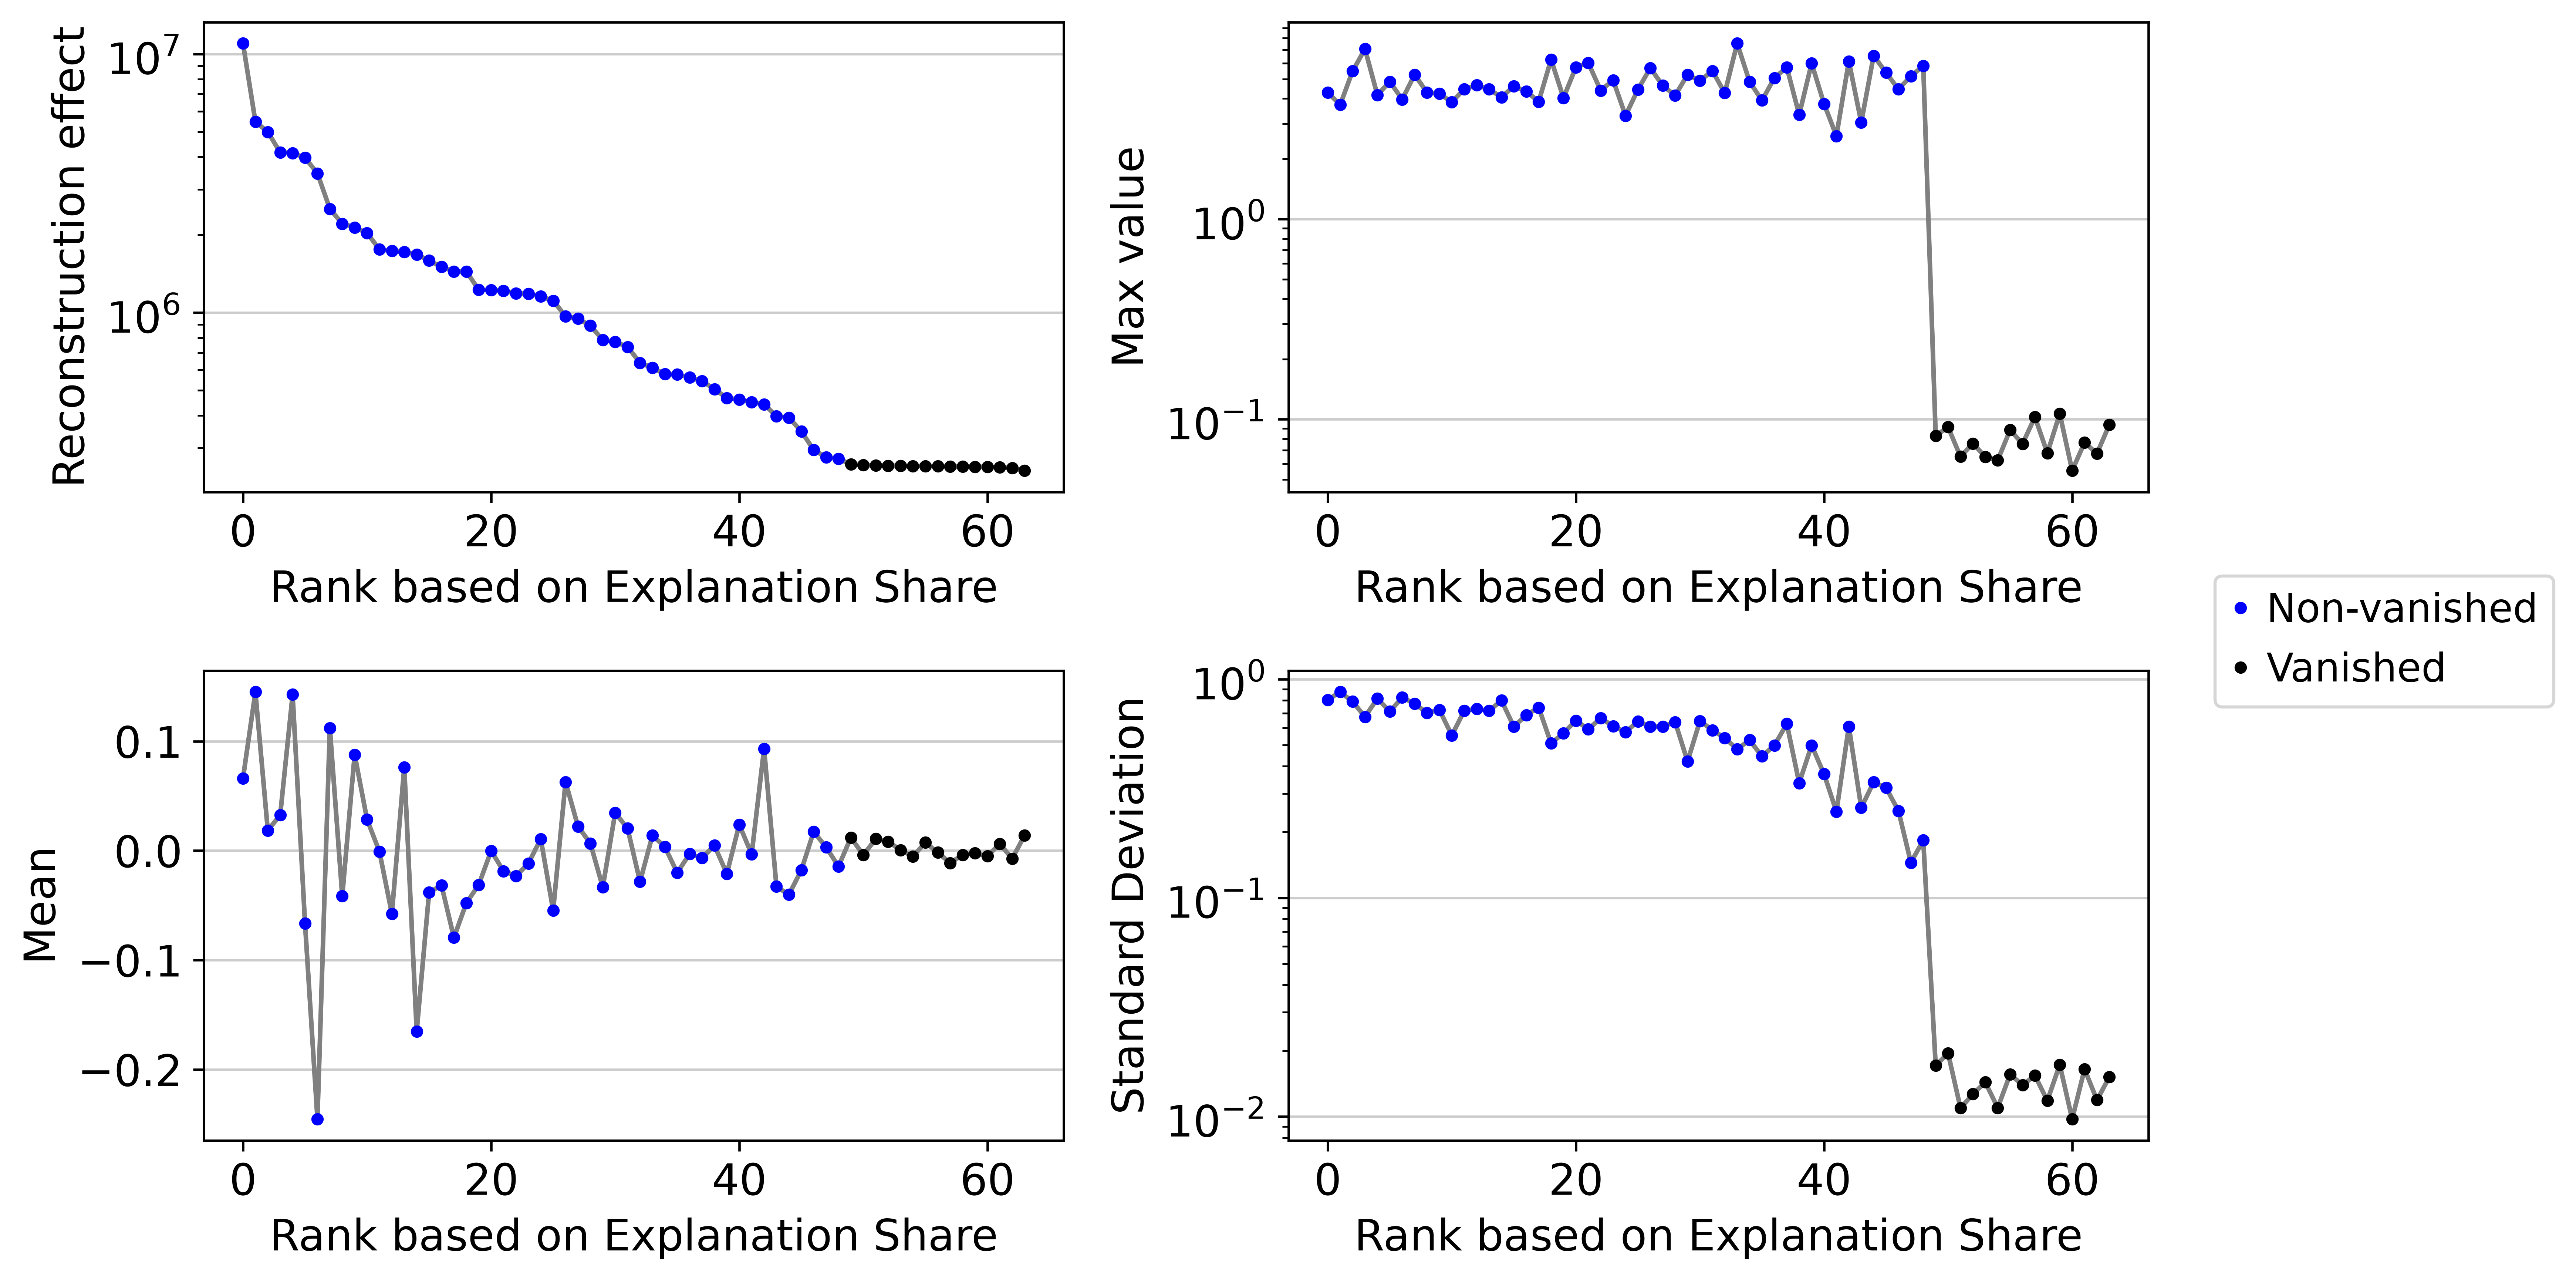

[fig] /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/figures/03_3_drvi_tum_64_nomt/latent_dimension_stats_drvi_tum_64_nomt.png


PosixPath('/home/catt/QCB-thesis-final/03_drvi_tumoral_epi/figures/03_3_drvi_tum_64_nomt/latent_dimension_stats_drvi_tum_64_nomt.png')

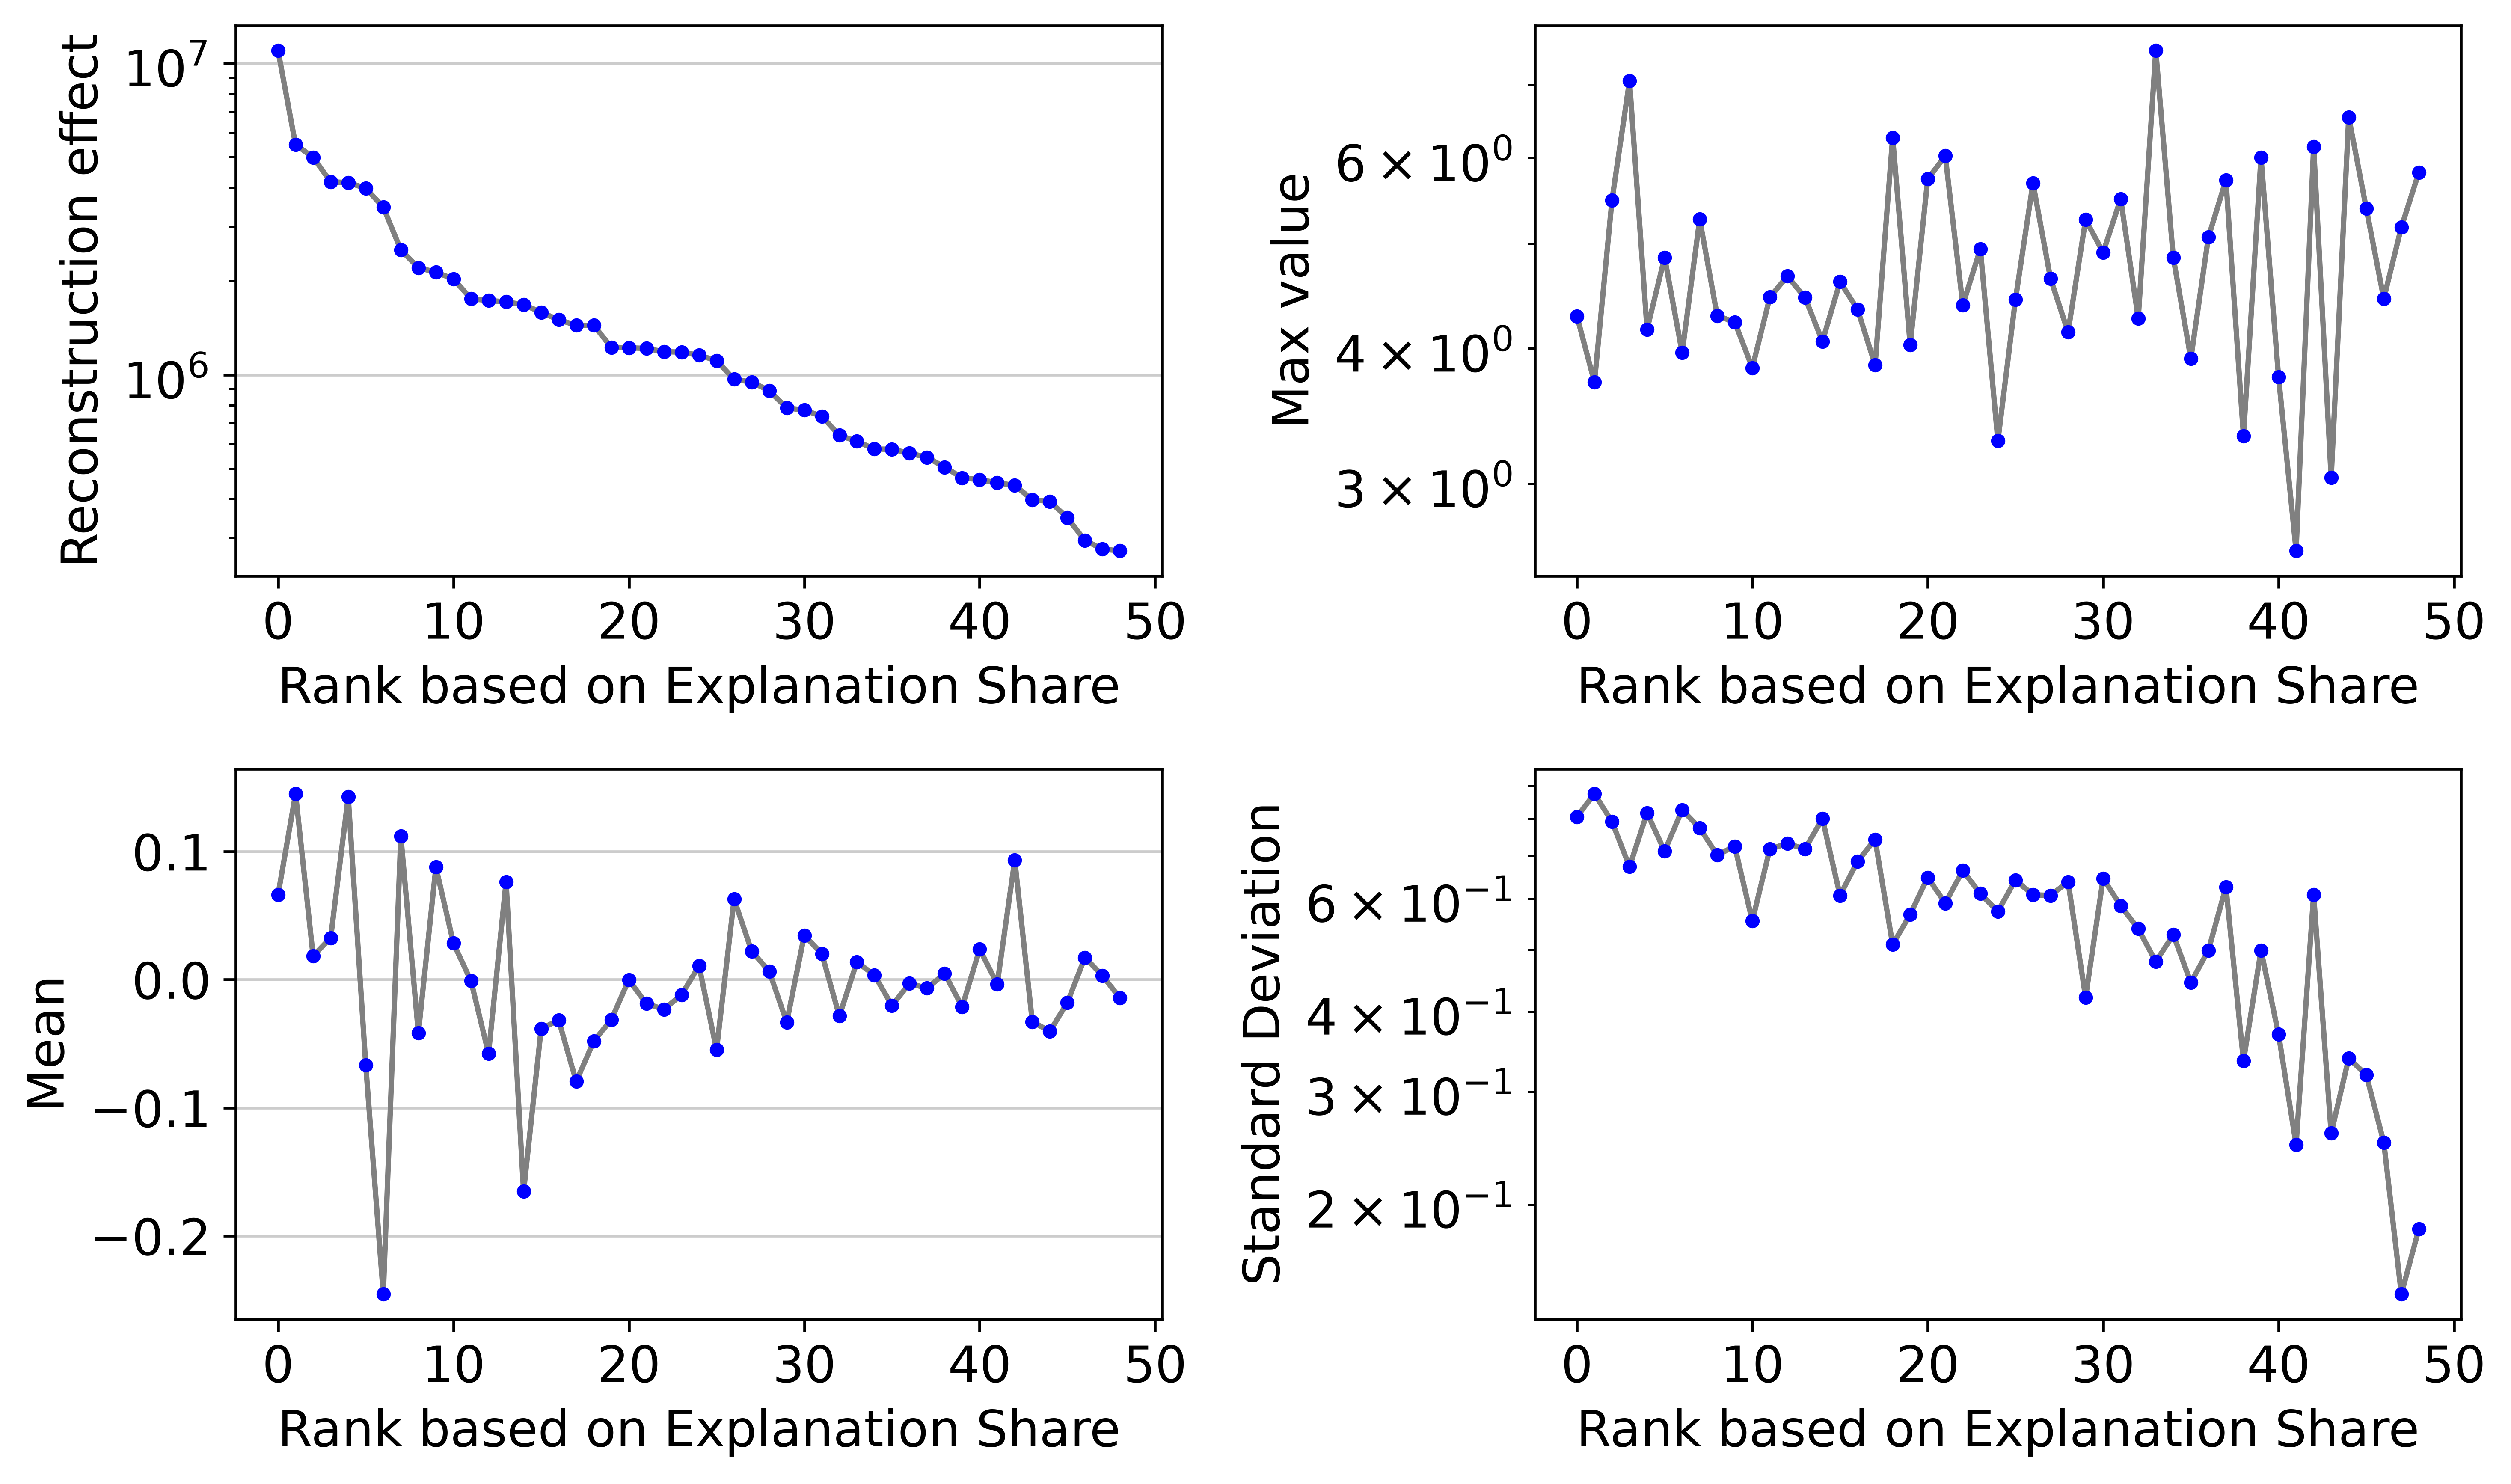

[fig] /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/figures/03_3_drvi_tum_64_nomt/latent_dimension_stats_rmVanished_drvi_tum_64_nomt.png


PosixPath('/home/catt/QCB-thesis-final/03_drvi_tumoral_epi/figures/03_3_drvi_tum_64_nomt/latent_dimension_stats_rmVanished_drvi_tum_64_nomt.png')

In [18]:
# Per-dimension statistics: reconstruction effect, max value, mean, std.
drvi.utils.pl.plot_latent_dimension_stats(embed, ncols=2, show=False)
savefig("latent_dimension_stats")

# The same, vanished dimensions dropped: the informative half of the plot above.
drvi.utils.pl.plot_latent_dimension_stats(embed, ncols=2, remove_vanished=True, show=False)
savefig("latent_dimension_stats_rmVanished")

In [ ]:
# Every non-vanished dimension on the UMAP 
drvi.utils.pl.plot_latent_dims_in_umap(embed, show=False)
savefig("latent_dims_in_umap")

### Which dimension responds to which group

One heatmap per grouping in GROUPING_KEYS, the constant columns already dropped, leiden
first. drvi_leiden says which dimensions carve the clusters of the DRVI space (circular: the
clusters were cut from these dimensions); a dimension that answers to a leiden cluster and to
nothing else is a tumor state.

cohort is the one to read defensively: this is the batch DRVI was told to correct, so a
dimension that responds to a single cohort is either residual batch or a tumor that really is
its own state - and with 20 patients those two are not separable here.

In [ ]:
# Sorted by category as well as by dimension: a group's own dimensions sit together, which
# makes it obvious when one group owns a whole dimension.
for key in GROUPING_KEYS:
    drvi.utils.pl.plot_latent_dims_in_heatmap(embed, key, title_col="title",
                                              sort_by_categorical=True, show=False)
    savefig(f"latent_dims_in_heatmap_{key}_sorted")
    plt.show()

### Interpretability (OOD scores)

*Taken from the DRVI tutorial [General training and interpretability pipeline](https://drvi.readthedocs.io/latest/tutorials/external/general_pipeline.html).*

The out-of-distribution scores come from the decoder reconstructions, so they are fast and
they favour the genes that are *specific* to a dimension.

In [ ]:
model.plot_interpretability_scores(embed, adata, show=False)
savefig("ood_interpretability_scores")
plt.show()

In [23]:
# Genes (rows) appear in adata order and are not sorted.
ood_scores = model.get_interpretability_scores(embed, adata)
ood_scores.iloc[:10, :10]

title,DR 1+,DR 1-,DR 2+,DR 2-,DR 3+,DR 3-,DR 4+,DR 4-,DR 5+,DR 5-
LTF,0.034698,9.095515e-09,7.728038e-05,2.394248e-05,0.000088,1.536164e-04,0.049698,3.502670e-08,6.851115e-06,3.085497e-06
UBE2C,0.010210,1.071046e-08,9.423247e+00,9.125074e-10,0.002212,6.420468e-03,0.003996,1.643826e-08,7.832475e-01,1.251920e-10
PTTG1,0.003892,4.695616e-08,8.798570e+00,1.445261e-09,0.008200,6.821509e-05,0.012377,1.447412e-07,6.006568e-02,4.191941e-09
CDC20,0.020416,1.542607e-08,1.164309e+01,1.936746e-09,0.000018,8.344871e-04,0.004296,3.009534e-08,7.852962e-02,6.109985e-10
CDK1,0.010360,1.091771e-08,5.549444e+00,2.081560e-09,0.000056,2.725323e-06,0.019740,3.798037e-08,1.652413e+00,9.827091e-11
CCNB1,0.014902,2.543078e-08,1.010655e+01,1.394934e-08,0.000054,7.791095e-04,0.006915,5.406361e-08,4.476289e-02,3.783691e-09
BIRC5,0.009685,3.057633e-08,5.348575e+00,1.457124e-10,0.015829,7.812565e-07,0.005009,3.963941e-08,1.023932e+00,4.937874e-10
CXCL10,0.015124,1.009585e-09,7.742967e-04,2.114996e-09,0.000302,1.032229e-05,0.713032,7.878509e-09,1.092100e-03,3.625166e-09
SPP1,0.002833,7.552820e-09,1.426474e-05,2.346897e-06,0.000032,3.351297e-03,10.242856,2.288564e-08,2.646905e-05,1.337004e-06
RNASE1,0.060995,2.189793e-08,2.358978e-07,1.631184e-06,0.005326,1.641894e-06,7.755235,1.037678e-07,2.474738e-07,1.432605e-06


*Taken from the DRVI tutorial [General training and interpretability pipeline](https://drvi.readthedocs.io/latest/tutorials/external/general_pipeline.html).*

The two halves of OOD_combined: the min_possible and max_possible log-fold-changes of each
dimension in the OOD setting. See the paper appendix for how they combine.

In [24]:
ood_max = model.get_interpretability_scores(embed, adata, key="OOD_max_possible")
ood_min = model.get_interpretability_scores(embed, adata, key="OOD_min_possible")
ood_max.iloc[:10, :10]
ood_min.iloc[:10, :10]

title,DR 1+,DR 1-,DR 2+,DR 2-,DR 3+,DR 3-,DR 4+,DR 4-,DR 5+,DR 5-
LTF,2.480889,0.001388,0.265847,0.150214,0.270965,0.358016,2.783541,0.002627,0.089422,0.043173
UBE2C,1.507030,0.001578,6.174284,0.000167,0.561053,1.304313,1.014596,0.001827,4.564047,0.000147
PTTG1,0.818682,0.002962,5.426658,0.000191,0.701281,0.130709,1.292239,0.004191,2.156965,0.000714
CDC20,1.525385,0.001554,5.558958,0.000164,0.066104,0.433880,0.857048,0.002098,2.347543,0.000273
CDK1,1.335225,0.001337,5.541892,0.000271,0.118841,0.030872,1.635539,0.001918,4.766973,0.000100
CCNB1,1.257490,0.002145,5.291899,0.000442,0.106853,0.372632,0.942001,0.002779,1.855501,0.000700
BIRC5,1.001485,0.001610,4.928379,0.000051,0.766331,0.011948,0.763784,0.001583,3.887396,0.000135
CXCL10,2.507903,0.000758,0.750861,0.001398,0.582254,0.152838,5.441262,0.001450,1.062916,0.002817
SPP1,1.246451,0.001330,0.113279,0.038230,0.088358,1.271074,6.709691,0.001184,0.158798,0.030000
RNASE1,2.595507,0.000880,0.005358,0.017020,0.940116,0.030277,5.957122,0.001001,0.009466,0.021305


title,DR 1+,DR 1-,DR 2+,DR 2-,DR 3+,DR 3-,DR 4+,DR 4-,DR 5+,DR 5-
LTF,0.013128,1.239777e-06,0.000232,1.434803e-04,0.000229,0.000399,0.017669,2.717972e-06,0.000067,4.358292e-05
UBE2C,0.006290,2.956391e-06,1.516602,1.573563e-06,0.001580,0.004669,0.003226,3.242493e-06,0.171225,2.384186e-07
PTTG1,0.004529,1.101494e-05,1.597532,3.361702e-06,0.005307,0.000482,0.009407,1.659393e-05,0.027272,2.574921e-06
CDC20,0.012654,5.865097e-06,2.088600,5.602837e-06,0.000218,0.001837,0.004658,7.772446e-06,0.033020,9.536743e-07
CDK1,0.007231,3.623962e-06,0.995480,2.336502e-06,0.000303,0.000078,0.011010,5.006790e-06,0.343726,2.861023e-07
CCNB1,0.011302,9.298325e-06,1.897931,1.440048e-05,0.000458,0.002003,0.006920,1.134872e-05,0.023710,2.956391e-06
BIRC5,0.008719,8.058548e-06,1.070157,7.152557e-07,0.009112,0.000058,0.005899,8.153916e-06,0.263012,1.001358e-06
CXCL10,0.005688,3.814697e-07,0.000670,7.152557e-07,0.000362,0.000066,0.130504,8.583069e-07,0.000925,1.239777e-06
SPP1,0.002169,1.382828e-06,0.000098,3.504753e-05,0.000100,0.002366,1.500953,3.838539e-06,0.000156,2.613068e-05
RNASE1,0.023323,4.291534e-06,0.000017,4.739761e-05,0.003662,0.000049,1.292659,1.380444e-05,0.000021,4.682541e-05


In [ ]:
model.plot_interpretability_scores(embed, adata, key="OOD_max_possible", show=False)
savefig("ood_max_interpretability_scores")
plt.show()

model.plot_interpretability_scores(embed, adata, key="OOD_min_possible", show=False)
savefig("ood_min_interpretability_scores")
plt.show()

### Interpretability (IND scores)

*Taken from the DRVI tutorial [General training and interpretability pipeline](https://drvi.readthedocs.io/latest/tutorials/external/general_pipeline.html).*

This approach iterates over all the cells and averages the effect of each latent factor on
each gene; the scores are already stored in embed.

They reflect the broad mechanistic effect of a dimension. Genes are not filtered for
uniqueness, so a gene shared by several dimensions keeps a high score in all of them: the
complete picture of what a factor moves, as opposed to the OOD scores' specific one.

In [ ]:
model.plot_interpretability_scores(embed, adata, key="IND_linear_weighted_mean", show=False)
savefig("ind_linear_weighted_mean")
plt.show()

In [27]:
# Genes (rows) appear in adata order and are not sorted.
ind_scores = model.get_interpretability_scores(embed, adata, key="IND_linear_weighted_mean")
ind_scores.iloc[:10, :10]

title,DR 1+,DR 1-,DR 2+,DR 2-,DR 3+,DR 3-,DR 4+,DR 4-,DR 5+,DR 5-
LTF,1.814095,0.000064,0.069191,7.368404e-02,0.066520,0.033170,0.747247,0.000058,0.019830,0.013926
UBE2C,1.150900,0.000939,3.800871,6.847871e-07,0.570524,0.246945,0.353133,0.000028,1.941578,0.000004
PTTG1,0.350853,0.002336,3.768591,2.947527e-07,0.605681,0.020434,0.201789,0.000276,0.473865,0.000114
CDC20,1.268918,0.001559,4.078622,6.139447e-07,0.046578,0.132977,0.296680,0.000123,0.848430,0.000033
CDK1,1.380028,0.001790,3.279695,8.732091e-06,0.085820,0.021128,0.521263,0.000065,2.757689,0.000006
CCNB1,1.168646,0.002160,3.931057,6.411753e-06,0.069250,0.122299,0.407386,0.000124,0.636507,0.000103
BIRC5,0.856466,0.001954,3.681156,7.587300e-08,1.081651,0.006610,0.251483,0.000197,1.296411,0.000012
CXCL10,1.506701,0.000213,0.325392,8.097407e-04,0.213509,0.013936,2.382703,0.000107,0.282217,0.003100
SPP1,1.077108,0.000108,0.025571,7.841367e-03,0.054520,0.119429,3.225808,0.000005,0.026007,0.008754
RNASE1,1.331306,0.000131,0.007569,1.530099e-02,1.788209,0.011052,2.540695,0.000012,0.010241,0.018221


## The subset in the DRVI space

embed above is the model's own view of the run - one var per latent dimension, its stats and
its interpretability scores - and by construction carries no genes. This is the other half:
the definitive 03_2 object (all genes, scran log-norm) with the latent space added as
obsm['X_drvi'] and the Leiden columns, for the downstream steps that need genes and latent coordinates in the same
object (03_5 cytotrace2, 03_6 cell-first). 03_4 works from the embedding
alone and does not open this file.

In [28]:
if OVERWRITE or not DOWNSTREAM_H5AD.exists():
    print(f"[read] {FULL_H5AD}")
    full = sc.read_h5ad(FULL_H5AD)

    # Realigned by cell name, not by order.
    assert set(embed.obs_names) == set(full.obs_names), \
        "the embedding and the 03_2 object disagree on cells"
    full.obsm["X_drvi"] = np.asarray(embed[full.obs_names].X, dtype=np.float32)
    assert np.isfinite(full.obsm["X_drvi"]).all()
    for key in LEIDEN_KEYS:
        full.obs[key] = embed.obs.loc[full.obs_names, key].values

    print(f"Writing {DOWNSTREAM_H5AD.name} (gzip, a few minutes) ...")
    full.write_h5ad(DOWNSTREAM_H5AD, compression="gzip")
    print(f"[write] {DOWNSTREAM_H5AD} "
          f"({full.n_obs:,} x {full.n_vars:,}, obsm['X_drvi'] {full.obsm['X_drvi'].shape}, "
          f"{DOWNSTREAM_H5AD.stat().st_size / 1024 ** 3:.2f} GB on disk)")
    del full
else:
    print(f"[have] {DOWNSTREAM_H5AD} (OVERWRITE=True to rewrite)")

[read] /home/catt/QCB-thesis-final/datasets/03_tum/shiao_tum.h5ad
Writing shiao_tum_drvi_tum_64_nomt.h5ad (gzip, a few minutes) ...
[write] /home/catt/QCB-thesis-final/datasets/03_tum/shiao_tum_drvi_tum_64_nomt.h5ad (41,943 x 25,197, obsm['X_drvi'] (41943, 64), 0.36 GB on disk)


## A closer look at the dimensions owned by a single group

The heatmaps above say *which* dimension responds to which group and latent_dims_in_umap
draws every surviving dimension at once, but neither answers the question one dimension at a
time: does a dimension that looks group-specific in the heatmap really light up that
population, and only that population? This section puts the two views side by side on the same
UMAP and with the same point order - the group on the left, the dimension on the right.

DRVI dimensions are directional: DR 20- is the *negative* half of dimension 20 and DR 20+
the positive one, the two halves are independent programs and in general only one of them
belongs to the group. The right panel is therefore coloured by the projection on the chosen
half (-z for a - dimension, the convention of
plot_latent_dims_in_umap(directional=True)), so a higher value always means *further along
the named direction*. The colour scale is the dimension's own range widened to at least
[-1, 1], so a weak dimension is not stretched to look strong.

Which pairs get drawn is decided by the SMI screening below, following the DRVI *Identifying
cell types of DRVI factors* tutorial, as in 02_2.

In [29]:
# Drawn on embed_plot (same point order and palettes as the UMAPs above), rebuilt if missing.
if "embed_plot" not in globals():
    _order = np.random.default_rng(globals().get("UMAP_SEED", SEED)).permutation(embed.n_obs)
    embed_plot = ad.AnnData(
        obs=embed.obs.iloc[_order].copy(),
        obsm={"X_umap": embed.obsm["X_umap"][_order]},
        uns={k: v for k, v in adata.uns.items() if k.endswith("_colors")},
    )
    print(f"[rebuilt] embed_plot: {embed_plot.n_obs:,} cells")
else:
    print(f"embed_plot: {embed_plot.n_obs:,} cells")

embed_plot: 41,943 cells


In [31]:
def dim_values(dim_title, direction):
    """The cells' projection on one half of a latent dimension, plus its colour range.

    `direction` is "+" or "-": for "-" the dimension is negated, so the returned values are
    large and positive exactly where the cells sit far along the negative half. The range
    follows DRVI: the dimension's own min / max, widened to at least [-1, 1].
    """
    hits = embed.var_names[embed.var["title"] == dim_title]
    if len(hits) != 1:
        raise KeyError(f"{dim_title!r} is not a dimension of this run")
    var_name = hits[0]

    sign = 1.0 if direction == "+" else -1.0
    values = pd.Series(np.asarray(embed[:, var_name].X).ravel(), index=embed.obs_names)

    lo, hi = float(embed.var.loc[var_name, "min"]), float(embed.var.loc[var_name, "max"])
    if sign < 0:
        lo, hi = -hi, -lo

    return sign * values, (min(lo, -1.0), max(hi, 1.0))


def plot_dim_vs_group(group, dim_title, direction, group_key=None, size=4, figsize=(11.5, 4.8)):
    """Two panels on the same UMAP: the group on the left, its dimension on the right.

    `group_key` is the obs column `group` is a level of - the leiden partition by default,
    never the constant `cell_type`. Both panels use `embed_plot`, so the point
    order and the palettes are the ones of every other UMAP in this notebook. Returns the
    figure, for `savefig`.
    """
    group_key = LEIDEN_KEY if group_key is None else group_key
    label = f"{dim_title}{direction}"
    values, (vmin, vmax) = dim_values(dim_title, direction)
    values = values.loc[embed_plot.obs_names]

    # A light companion object: only the UMAP and the one column to colour by.
    panel = ad.AnnData(
        obs=pd.DataFrame({label: values.to_numpy()}, index=embed_plot.obs_names),
        obsm={"X_umap": embed_plot.obsm["X_umap"]},
    )

    # No tight_layout here: it collapses the colour bar sc.pl.umap attaches to `ax`.
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    sc.pl.umap(embed_plot, color=group_key, groups=[group], title=f"{group} ({group_key})",
               ax=axes[0], show=False, legend_loc="none", na_in_legend=False,
               size=size, frameon=False)
    sc.pl.umap(panel, color=label, title=label, ax=axes[1], show=False,
               size=size, frameon=False, cmap=drvi.utils.pl.cmap.saturated_sky_cmap,
               vmin=vmin, vcenter=0, vmax=vmax)

    # The number behind the picture: the same contrast the heatmap shows as one cell.
    in_group = embed_plot.obs[group_key].astype(str).to_numpy() == str(group)
    print(f"{label}: {values[in_group].mean():+.2f} mean over the {int(in_group.sum()):,} "
          f"cells of {group_key}={group} vs {values[~in_group].mean():+.2f} over the other "
          f"{int((~in_group).sum()):,}")
    return fig

### Which factor encodes which group: SMI

The first question is whether the Leiden clusters and the DRVI dimensions agree: does each
cluster have a factor direction of its own? Agreement is very likely, because the clusters were
computed on these same dimensions, so the comparison is circular. The DRVI tutorial measures
this one-to-one correspondence with the Scaled Mutual Information (SMI), normalized to [0, 1].

*Taken from the DRVI tutorial [Identifying cell types of DRVI factors](https://drvi.readthedocs.io/latest/tutorials/external/identification_of_factors_1_cell_types.html).*

Three steps:

- build_directional_df turns the latent space into a *cells x factor-directions* matrix.
  Each dimension is split in two, the vanished halves are dropped, and each half is clipped
  at zero (pos = z.clip(min=0), neg = -z.clip(max=0)): the positive half reads zero
  wherever the factor is negative and vice versa, so the two halves become two independent
  variables, each switched off outside its own semiaxis.
- smi_matches hands that matrix to DiscreteDisentanglementBenchmark with metrics=["SMI"].
  Internally each direction is binned into 10 uniform bins and the mutual information between
  the binned factor and the one-hot indicator of each group is divided by that group's entropy
  - the normalisation that makes a rare group and an abundant one comparable.
- store_matches writes the best match per direction back into embed.var as
  positive_direction_match_with_\<suffix\> / negative_direction_match_with_\<suffix\> and the
  whole table into embed.uns, the layout the other notebooks of the tutorial series read.

Run against one target, drvi_leiden. cell_type is constant here, so the tutorial's own target
does not exist on this object and SMI against it is zero by construction. The leiden partition
is circular - the clusters were cut from these factors, so a match is expected - and what it
adds is which direction owns which cluster one to one (the screening 03_8 also runs).

What SMI measures is the agreement between a factor and *a grouping* - not between
a factor and the truth - so a mediocre score can be the grouping's fault as much as the
factor's, and the assignments are worth checking against each dimension's own panel below.

In [32]:
# Imports local to this section, so the Libraries cell at the top does not have to be re-run:
# `networkx` and the benchmark class are only used here.
import networkx as nx
from drvi.utils.metrics import DiscreteDisentanglementBenchmark


def build_directional_df(embed):
    """Cells x (non-vanished factor-directions). Column names carry a '+'/'-' suffix."""
    embed_pos = embed[:, ~embed.var["vanished_positive_direction"]].copy()
    embed_neg = embed[:, ~embed.var["vanished_negative_direction"]].copy()
    embed_pos.var.index = embed_pos.var["title"] + "+"
    embed_neg.var.index = embed_neg.var["title"] + "-"
    embed_pos.X = embed_pos.X.clip(min=0)
    embed_neg.X = -embed_neg.X.clip(max=0)
    return pd.concat([embed_pos.to_df(), embed_neg.to_df()], axis=1).loc[embed.obs.index]


def smi_matches(embed_directional_df, target, threshold):
    """SMI between every factor-direction and every category of `target`.

    Returns (full SMI matrix, long table of pairs with SMI >= threshold sorted descending).
    """
    benchmark = DiscreteDisentanglementBenchmark(
        embed_directional_df.values,
        dim_titles=embed_directional_df.columns,
        discrete_target=target,
        metrics=["SMI"],
        aggregation_methods=[],
    )
    benchmark.evaluate()
    smi = benchmark.get_results_details()["SMI"]
    smi.index.name = "title"

    top = (
        smi.reset_index()
        .melt(id_vars="title", value_vars=smi.columns)
        .query("value >= @threshold")
        .reset_index(drop=True)
        .sort_values("value", ascending=False)
    )
    return smi, top


def store_matches(embed, top, suffix):
    """Store the best match per factor-direction in `embed.var` and the full table in `.uns`."""
    first = top.drop_duplicates(subset=["title"]).copy()
    first["direction"] = first["title"].str[-1:]
    first["title"] = first["title"].str[:-1]

    embed.var.set_index("title", drop=False, inplace=True)
    for d, sign in [("positive", "+"), ("negative", "-")]:
        col = f"{d}_direction_match_with_{suffix}"
        embed.var[col] = None
        sub = first.query("direction == @sign")
        embed.var.loc[sub["title"], col] = sub["variable"].values
    embed.var.index = embed.var["original_dim_id"].astype(int).astype(str)
    embed.var.index.name = None

    embed.uns[f"best_smi_matching_{suffix}_results"] = top


def plot_packed_network(df, title_col="title", var_col="variable", val_col="value",
                        figsize=(20, 20)):
    """Visualize factor-group associations as a network with edge weights."""
    G = nx.from_pandas_edgelist(df, title_col, var_col, edge_attr=val_col)

    pos = {}
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    cols = 3
    for i, nodes in enumerate(components):
        sub_pos = nx.spring_layout(G.subgraph(nodes), weight=val_col, k=0.5, seed=SEED)
        r, c = divmod(i, cols)
        for n, (x, y) in sub_pos.items():
            pos[n] = (x + c * 3, y - r * 3)

    plt.figure(figsize=figsize)
    titles = set(df[title_col])
    weights = [d[val_col] for u, v, d in G.edges(data=True)]
    nx.draw(
        G, pos,
        with_labels=True, font_size=8, font_weight="bold", node_size=600,
        node_color=["#A0CBE2" if n in titles else "#FF9E9E" for n in G.nodes()],
        width=[w * 4 for w in weights],
        edge_color=weights, edge_cmap=plt.cm.Oranges, alpha=0.6,
    )
    edge_labels = {(u, v): f"{d[val_col]:.2f}" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)
    plt.axis("off")

In [47]:
# SMI at which a direction explains a cluster, as in 03_8.
SMI_THRESHOLD = 0.7

# ~42k cells: seconds, against the ~11 minutes the same cell takes on the 620k cells of 02_2.
embed_directional_df = build_directional_df(embed)
print(f"{embed_directional_df.shape[1]} non-vanished factor directions "
      f"out of {2 * embed.n_vars}")

97 non-vanished factor directions out of 128


In [48]:
# `cell_type` is deliberately not a target: it is constant on this object, and SMI against a
# constant is zero everywhere.
SMI_TARGETS = {"leiden": LEIDEN_KEY} if HAS_LEIDEN else {}

smi_similarity, smi_top_matches = {}, {}
for suffix, key in SMI_TARGETS.items():
    threshold = SMI_THRESHOLD
    smi_similarity[suffix], smi_top_matches[suffix] = smi_matches(
        embed_directional_df, embed.obs[key], threshold
    )
    print(f"{suffix:>16} ({key}): SMI matrix {smi_similarity[suffix].shape}, "
          f"{len(smi_top_matches[suffix])} pairs >= {threshold}, "
          f"best {smi_similarity[suffix].to_numpy().max():.3f}")

smi_top_matches[list(SMI_TARGETS)[0]].head(20)

          leiden (drvi_leiden): SMI matrix (97, 34), 7 pairs >= 0.7, best 0.900


,title,variable,value
5,DR 41-,30,0.899702
4,DR 19-,29,0.886151
1,DR 33+,16,0.872065
6,DR 44+,32,0.856671
0,DR 6-,8,0.789826
3,DR 11-,26,0.774479
2,DR 30-,20,0.764516


In [37]:
# The matches as a bipartite graph, one per target: components beyond a single edge are a
# group carried by two factors, or a factor shared by two groups.
for suffix, top in smi_top_matches.items():
    if top.empty:
        print(f"[skip] {suffix}: no pair above {SMI_THRESHOLD}")
        continue
    plot_packed_network(top, figsize=(20, 20))
    savefig(f"smi_{suffix}_network")
    plt.show()

[fig] /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/figures/03_3_drvi_tum_64_nomt/smi_leiden_network_drvi_tum_64_nomt.png


PosixPath('/home/catt/QCB-thesis-final/03_drvi_tumoral_epi/figures/03_3_drvi_tum_64_nomt/smi_leiden_network_drvi_tum_64_nomt.png')

In [38]:
# Best match per direction into embed.var, whole table into embed.uns, as the tutorial does;
# the suffix names the target.
for suffix, top in smi_top_matches.items():
    if top.empty:
        continue
    store_matches(embed, top, suffix=suffix)

[c for c in embed.var.columns if "direction_match_with" in c]

['positive_direction_match_with_leiden',
 'negative_direction_match_with_leiden']

In [39]:
# A copy of the tables in TABLE_DIR; rewriting LATENT_H5AD (a few hundred MB) is opt-in.
for suffix, top in smi_top_matches.items():
    path = TABLE_DIR / f"smi_{suffix}_matches_{RUN_ID}.csv"
    top.to_csv(path, index=False)
    print(f"[write] {path} ({len(top)} rows)")

WRITE_BACK_EMBED = False
if WRITE_BACK_EMBED:
    ad.settings.allow_write_nullable_strings = True
    embed.write_h5ad(LATENT_H5AD)
    print(f"[write] {LATENT_H5AD}")

[write] /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/tables/03_3_drvi_tum_64_nomt/smi_leiden_matches_drvi_tum_64_nomt.csv (7 rows)


### The pairs, one at a time

Every match above, as the two-panel figure: the group on the left, the factor direction SMI
paired it with on the right. A high SMI says the two carry the same information.

In [ ]:
# `title` carries the direction as its last character: "DR 18-" -> ("DR 18", "-").
for suffix, top in smi_top_matches.items():
    group_key = SMI_TARGETS[suffix]
    for row in top.itertuples(index=False):
        dim_title, direction, group = row.title[:-1], row.title[-1], row.variable
        print(f"[{suffix}] SMI {row.value:.3f}", end="  ")
        fig = plot_dim_vs_group(group, dim_title, direction, group_key=group_key)
        savefig(f"dim_vs_{suffix}_{group}_{dim_title.replace(' ', '')}{direction}", fig=fig)
        plt.show()

## What the factors are doing: biological processes

SMI only finds the dimensions that match a single cluster. We are also interested in the
dimensions that span several groups of cells: shared programs such as secretion, interferon
response, cell cycle or stress, which SMI does not reward. These can be found with enrichment,
naming each dimension by its top genes.

In this phase the enrichment is the main reading: there is no biological annotation of the
cells, so the genes are the only way to name a dimension without going back to the latent
space. The SMI matches are a cross-check.

*Taken from the DRVI tutorial [Identifying biological processes of DRVI factors](https://drvi.readthedocs.io/latest/tutorials/external/identification_of_factors_2_biological_processes.html).*

This is the DRVI tutorial *Identifying biological processes of DRVI factors*, run on this
notebook's factors. Three non-LLM tools, all reading the same per-gene interpretability scores
computed above:

| Tool | Method | Input | What it adds |
| --- | --- | --- | --- |
| Enrichr (via GSEApy) | over-representation (ORA) | top-N gene list | fast, the largest library collection |
| g:Profiler | over-representation (ORA) | ordered gene query | g:SCS correction, built for the GO hierarchy |
| decoupler | activity inference (ULM/MLM) | gene-score matrix + prior network | reports *regulators* (TFs), not terms |

Three things to keep in mind, none of them a departure from the tutorial:

- The background is the HVG panel, 2,000 genes. ORA asks "is this term over-represented in
  the top genes *relative to the universe those genes were drawn from*", and that universe is
  whatever DRVI was trained on: the interpretability table has one row per model gene and no
  others, so there is no wider list to test against. The tutorial does the same
  (gene_background = adata.var_names.tolist()); what changes here is how that panel was
  chosen - 2,000 genes selected in 03_2 inside the tumor, so the terms found are found
  among the genes that vary most between malignant cells, not between tumor and normal. It is
  a ceiling on coverage, not a bias: a process whose genes are mostly outside the panel cannot
  be found. Letting the tools fall back to their whole-genome default would be the wrong call -
  it would count the HVG selection itself as enrichment.
- The scores are the OOD ones (OOD_combined), which favour genes *specific* to a
  direction. IND_linear_weighted_mean is the alternative and needs a higher cutoff, ~0.5
  against ~0.1 - see the config cell.
- Pre-ranked GSEA is not run. DRVI's scores are non-negative by construction, one ranking
  per factor *direction*, so there is no signed bottom of the list for GSEA to use. The
  tutorial makes the same call: ORA plus TF activity, no GSEA.

Everything here is guiding. A term is a hypothesis about a factor, to be read next to the
factor's top genes and the groups it lights up, not a conclusion.

### Setup

Both ORA tools query a web service (Enrichr for the library, g:Profiler for the whole run), so
these cells need network and are the slow ones of the notebook. The imports are local to the
section, as in the SMI one, so the Libraries cell at the top does not have to be re-run.

In [51]:
# Local imports: only this section uses them.
import gseapy
from gprofiler import GProfiler
import decoupler as dc
from statsmodels.stats.multitest import multipletests

In [52]:
SCORE_KEY = "OOD_combined"   # or "IND_linear_weighted_mean", with the higher cutoffs below

# The gene x factor-direction table every tool below reads.
scores_df = model.get_interpretability_scores(embed, adata, key=SCORE_KEY)

# The universe the top genes are drawn from: the 2,000 HVGs of INPUT_H5AD, nothing else.
gene_background = adata.var_names.tolist()

print(f"{scores_df.shape[0]:,} genes x {scores_df.shape[1]} factor directions, key={SCORE_KEY!r}")
print(f"background  {len(gene_background):,} genes (the HVG panel of 03_2, selected inside the tumor)")

2,000 genes x 97 factor directions, key='OOD_combined'
background  2,000 genes (the HVG panel of 03_2, selected inside the tumor)


In [53]:
def top_genes(scores_df, col, cutoff, top_n):
    """Genes of a factor direction with score >= cutoff, at most `top_n`, best first."""
    s = scores_df[col]
    return s[s >= cutoff].nlargest(top_n).index.astype(str).tolist()


def factor_first(df):
    """`df` with the `factor` column moved to the front (no-op if empty or absent)."""
    if df.empty or "factor" not in df.columns:
        return df
    return df[["factor", *df.columns.drop("factor")]]


# How many directions carry a gene list at all, at the cutoff used below: a direction whose
# best gene sits under the cutoff has no program to test and is skipped by every tool.
GENE_CUTOFF = 0.1 if SCORE_KEY == "OOD_combined" else 0.5   # ~0.1 for OOD, ~0.5 for IND
TOP_N = 100                                              # max genes per direction

sizes = pd.Series(
    {c: len(top_genes(scores_df, c, GENE_CUTOFF, TOP_N)) for c in scores_df.columns},
    name="n_genes",
)
print(f"directions with at least one gene past {GENE_CUTOFF}: "
      f"{(sizes > 0).sum()} / {len(sizes)}")
print(f"median list length among those: {int(sizes[sizes > 0].median()) if (sizes > 0).any() else 0} genes")
sizes.sort_values(ascending=False).head(10)

directions with at least one gene past 0.1: 57 / 97
median list length among those: 55 genes


DR 1+     100
DR 2+     100
DR 4+     100
DR 5+     100
DR 6-     100
DR 8+     100
DR 14+    100
DR 12-    100
DR 9-     100
DR 13-    100
Name: n_genes, dtype: int64

### 1. Enrichr (via GSEApy)

*Taken from the DRVI tutorial [Identifying biological processes of DRVI factors](https://drvi.readthedocs.io/latest/tutorials/external/identification_of_factors_2_biological_processes.html).*

The plain over-representation test: take the top genes of a direction, ask whether any term of
a library is over-represented among them against the background, Benjamini-Hochberg over the
terms of that direction.

GO_Biological_Process_2023 is the tutorial's library. The appendix of the tutorial lists the
swap-ins - MSigDB_Hallmark_2020 for broad states, Reactome_Pathways_2024, KEGG_2026,
CellMarker_2024 and PanglaoDB_Augmented_2021 for markers - and only GSEAPY_DB has to
change to use one. The library is fetched from Enrichr the first time, so this cell needs
network.

In [54]:
GSEAPY_DB = "GO_Biological_Process_2023"   # any Enrichr library, see the tutorial appendix
PADJ_THRESHOLD = 0.05


def run_gseapy_enrichr(scores_df, gene_sets, cutoff, top_n, padj_cutoff, background):
    rows = []
    for col in scores_df.columns:
        genes = top_genes(scores_df, col, cutoff, top_n)
        if not genes:
            continue
        try:
            enr = gseapy.enrich(gene_list=genes, gene_sets=gene_sets, background=background,
                                no_plot=True, outdir=None)
        except Exception as e:
            print(f"ORA failed for {col}: {e}")
            continue
        hits = enr.results[enr.results["Adjusted P-value"] < padj_cutoff]
        rows.append(hits.assign(factor=col))
    return factor_first(pd.concat(rows, ignore_index=True)) if rows else pd.DataFrame()


enrichr_results = run_gseapy_enrichr(
    scores_df, GSEAPY_DB, GENE_CUTOFF, TOP_N, PADJ_THRESHOLD, gene_background
)
n_sig = enrichr_results["factor"].nunique() if not enrichr_results.empty else 0
print(f"Enrichr: {n_sig} / {scores_df.shape[1]} factor directions with at least one term "
      f"at padj < {PADJ_THRESHOLD}")
enrichr_results.head()

Enrichr: 46 / 97 factor directions with at least one term at padj < 0.05


,factor,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
0,DR 1+,GO_Biological_Process_2023,Extracellular Matrix Organization (GO:0030198),7.265223e-11,6.139113e-08,0,0,10.207317,238.293257,POSTN;COL15A1;LUM;MMP1;MMP2;COL11A1;COL12A1;DP...
1,DR 1+,GO_Biological_Process_2023,External Encapsulating Structure Organization ...,5.800355e-10,1.633767e-07,0,0,13.285137,282.547377,POSTN;COL15A1;MMP1;MMP2;COL11A1;COL1A1;MMP11;C...
2,DR 1+,GO_Biological_Process_2023,Extracellular Structure Organization (GO:0043062),5.800355e-10,1.633767e-07,0,0,13.285137,282.547377,POSTN;COL15A1;MMP1;MMP2;COL11A1;COL1A1;MMP11;C...
3,DR 1+,GO_Biological_Process_2023,Collagen Fibril Organization (GO:0030199),2.384276e-08,5.036784e-06,0,0,23.390110,410.538180,COL1A1;COL3A1;COL1A2;COL5A1;LUM;COL11A1;COL12A...
4,DR 1+,GO_Biological_Process_2023,Regulation Of Glycoprotein Biosynthetic Proces...,1.214524e-04,2.052546e-02,0,0,inf,inf,CCL21;CCL19;IGF1


In [57]:
# One row per factor direction: its single most significant term.
enrichr_top = (
    enrichr_results.sort_values("Adjusted P-value")
    .drop_duplicates(subset=["factor"], keep="first")
    [["factor", "Term", "Adjusted P-value", "Odds Ratio", "Genes"]]
    if not enrichr_results.empty else pd.DataFrame()
)
enrichr_top

,factor,Term,Adjusted P-value,Odds Ratio,Genes
815,DR 31+,Defense Response To Virus (GO:0051607),4.790617e-28,66.785806,IFITM3;IFITM1;IFI6;DDX60L;IFIT1;DDX60;SAMHD1;I...
12,DR 2+,Mitotic Sister Chromatid Segregation (GO:0000070),8.785494e-27,126.333333,KIF14;CDCA8;NCAPG;KIF11;SMC4;SMC2;CCNB1;NUSAP1...
1051,DR 43+,Cellular Response To Zinc Ion (GO:0071294),3.031100e-21,inf,MT2A;MT1A;MT1M;MT1F;MT1G;MT1X;MT1H;MT1E
259,DR 5+,DNA Metabolic Process (GO:0006259),8.243943e-17,33.405063,TOP2A;FEN1;RNASEH2A;RFC4;MCM7;RFC2;HMGB2;NUDT1...
504,DR 19-,T Cell Activation (GO:0042110),3.638125e-14,24.750000,ITK;RHOH;CD3G;PTPN22;NLRC3;CD3E;SLA2;CD3D;CD2;...
459,DR 15-,Antigen Processing And Presentation Of Exogeno...,1.231726e-13,113.678049,HLA-DMA;HLA-DRB5;HLA-DMB;HLA-DRA;HLA-A;HLA-F;H...
392,DR 14+,Defense Response To Virus (GO:0051607),2.020532e-13,17.581197,IFITM3;GBP5;IFITM1;STAT1;MX1;ISG15;SAMHD1;IFIT...
352,DR 7-,Regulation Of Transcription By RNA Polymerase ...,1.469245e-11,7.046363,CEBPD;CITED2;DNAJB1;ZFP36;MYC;HES1;JUNB;IER2;S...
159,DR 4+,Inflammatory Response (GO:0006954),4.827904e-10,10.654631,CXCL8;CCL3L1;ITGB2;FPR1;CYBB;FPR3;LYZ;CXCL3;AI...
951,DR 37-,Intermediate Filament Organization (GO:0045109),5.414636e-10,74.346154,KRT17;KRT16;KRT15;KRT14;PKP1;KRT23;KRT5;KRT75;...


*Taken from the DRVI tutorial [Identifying biological processes of DRVI factors](https://drvi.readthedocs.io/latest/tutorials/external/identification_of_factors_2_biological_processes.html).*

How to read this. ORA is only as good as the library and as the gene list. A direction whose
biology is well covered by GO returns terms that are specific and internally consistent (a
secretory factor returning secretion / hormone terms, not one secretion term surrounded by
noise); a direction whose biology is not covered returns whatever loosely overlaps. The check is
the g:Profiler run below: a term that both ORA tools return, with different multiple-testing
machinery, is worth more than a term either returns alone.

One expectation specific to this subset: the cell cycle will be there. phase is not constant, and proliferation is the most reliably enriched process
in any tumor compartment. A dimension whose top terms are mitotic is a real finding about the
axis - and it is also the confound 03_6 recomputes its target region inside G1 to measure. Read
those two together.

### 2. g:Profiler

*Taken from the DRVI tutorial [Identifying biological processes of DRVI factors](https://drvi.readthedocs.io/latest/tutorials/external/identification_of_factors_2_biological_processes.html).*

The same over-representation question, two things done differently. The correction is g:SCS
rather than BH: GO terms are nested, so the tests are not independent and BH is anti-conservative
on them; g:SCS is calibrated on random queries against the actual GO graph. And the query is
ordered - the ranked gene list is walked and the best-enriched prefix is kept - which suits a
continuous score better than a hard top-100 cut.

Coverage is usually lower than Enrichr's. That is the point of running both.

In [58]:
ORGANISM = "hsapiens"
GP_SOURCE = ["GO:BP"]        # e.g. ["GO:MF"], ["REAC"], ["KEGG"], ["HP"]
PVAL_THRESHOLD = 0.05


def run_gprofiler(scores_df, background, organism, sources, pval_threshold, cutoff, top_n):
    gp = GProfiler(return_dataframe=True)
    rows = []
    for col in scores_df.columns:
        genes = top_genes(scores_df, col, cutoff, top_n)
        if not genes:
            continue
        res = gp.profile(organism=organism, query=genes, sources=sources, ordered=True,
                         user_threshold=pval_threshold, background=background)
        if res is None or res.empty:
            continue
        rows.append(res.assign(factor=col))
    return factor_first(pd.concat(rows, ignore_index=True)) if rows else pd.DataFrame()


gprofiler_results = run_gprofiler(
    scores_df, gene_background, ORGANISM, GP_SOURCE, PVAL_THRESHOLD, GENE_CUTOFF, TOP_N
)
if not gprofiler_results.empty:
    # `parents` is a list per row and h5ad cannot store that, so it is flattened now.
    gprofiler_results["parents"] = gprofiler_results["parents"].astype(str)

n_sig = gprofiler_results["factor"].nunique() if not gprofiler_results.empty else 0
print(f"g:Profiler: {n_sig} / {scores_df.shape[1]} factor directions with at least one term "
      f"at p < {PVAL_THRESHOLD}")
gprofiler_results.sort_values(["factor", "p_value"]).head() if not gprofiler_results.empty else None

g:Profiler: 14 / 97 factor directions with at least one term at p < 0.05


,factor,source,native,name,p_value,significant,description,term_size,query_size,intersection_size,effective_domain_size,precision,recall,query,parents
0,DR 1+,GO:BP,GO:0030199,collagen fibril organization,3.666223e-04,True,"""Any process that determines the size and arra...",28,10,7,1878,0.700000,0.250000,query_1,['GO:0030198']
62,DR 15-,GO:BP,GO:0002504,antigen processing and presentation of peptide...,5.992386e-12,True,"""The process in which an antigen-presenting ce...",20,9,9,1878,1.000000,0.450000,query_1,['GO:0019882']
63,DR 15-,GO:BP,GO:0048002,antigen processing and presentation of peptide...,3.925575e-11,True,"""The process in which an antigen-presenting ce...",27,15,12,1878,0.800000,0.444444,query_1,['GO:0019882']
64,DR 15-,GO:BP,GO:0002503,peptide antigen assembly with MHC class II pro...,1.900080e-10,True,"""The binding of a peptide to the antigen bindi...",9,9,7,1878,0.777778,0.777778,query_1,"['GO:0002399', 'GO:0002495', 'GO:0002501']"
65,DR 15-,GO:BP,GO:0002399,MHC class II protein complex assembly,1.900080e-10,True,"""The aggregation, arrangement and bonding toge...",9,9,7,1878,0.777778,0.777778,query_1,['GO:0002396']


In [59]:
# One row per factor direction: its single most significant term.
gprofiler_top = (
    gprofiler_results.sort_values("p_value")
    .drop_duplicates(subset=["factor"], keep="first")
    [["factor", "native", "name", "p_value", "term_size", "query_size", "intersection_size"]]
    if not gprofiler_results.empty else pd.DataFrame()
)
gprofiler_top

,factor,native,name,p_value,term_size,query_size,intersection_size
110,DR 34+,GO:0002250,adaptive immune response,2.194786e-16,247,89,78
125,DR 43+,GO:0010273,detoxification of copper ion,3.971594e-14,8,8,8
1,DR 2+,GO:0000070,mitotic sister chromatid segregation,6.378162e-13,55,96,41
62,DR 15-,GO:0002504,antigen processing and presentation of peptide...,5.992386e-12,20,9,9
94,DR 31+,GO:0045071,negative regulation of viral genome replication,5.367592e-09,23,38,14
84,DR 29+,GO:0019885,antigen processing and presentation of endogen...,5.456479e-05,8,12,6
113,DR 37-,GO:0045109,intermediate filament organization,1.665610e-04,16,6,6
118,DR 38-,GO:0009408,response to heat,3.044978e-04,15,8,7
0,DR 1+,GO:0030199,collagen fibril organization,3.666223e-04,28,10,7
82,DR 23-,GO:0006953,acute-phase response,7.131226e-04,18,41,10


*Taken from the DRVI tutorial [Identifying biological processes of DRVI factors](https://drvi.readthedocs.io/latest/tutorials/external/identification_of_factors_2_biological_processes.html).*

How to read this. The hits of one factor tend to organise general-to-specific, and the
specific end is where g:Profiler earns its place: it can name the mechanism where Enrichr names
the compartment. Read the two tables side by side - the summary further down does exactly that -
and trust the convergent calls.

### 3. decoupler

*Taken from the DRVI tutorial [Identifying biological processes of DRVI factors](https://drvi.readthedocs.io/latest/tutorials/external/identification_of_factors_2_biological_processes.html).*

A different question from the two above. ORA asks whether a gene list overlaps a term; decoupler
takes the whole score vector of a direction and asks which regulator would explain it, by
scoring each TF regulon of a prior network with a linear model (ULM) and a multivariate one
(MLM), then taking the consensus. A significant hit is a transcription factor whose targets carry
the factor's program - a mechanistic layer neither ORA tool can give.

The networks come from OmniPath: CollecTRI (comprehensive TF to target regulons, the default
here), DoRothEA (the same with confidence tiers A-D), PROGENy (pathway footprints, for
signalling rather than TFs).

The 2,000-gene panel bites hardest here. A regulon is only usable if enough of its targets
survived HVG selection, so the network is intersected with the panel before anything is inferred
and DC_MIN decides how many targets are enough. The cell prints what survives; if that number
is small, lower DC_MIN to 5 before reading anything into the coverage.

In [60]:
DC_GENESET = "collectri"     # or "dorothea", "progeny"
DC_ORGANISM = "human"
DC_CUTOFF = 0.01 if SCORE_KEY == "OOD_combined" else 0.05   # scores under this read as zero
FDR_THRESHOLD = 0.05
DC_METHODS = ["ulm", "mlm"]
DC_MIN = 10                  # min targets of a regulon present in the HVG panel
DOROTHEA_LEVELS = ["A", "B", "C"]
FDR_METHOD = "fdr_bh"

net_dispatch = {
    "collectri": lambda: dc.op.collectri(organism=DC_ORGANISM),
    "dorothea": lambda: dc.op.dorothea(organism=DC_ORGANISM, levels=DOROTHEA_LEVELS),
    "progeny": lambda: dc.op.progeny(organism=DC_ORGANISM),
}
net = net_dispatch.get(
    DC_GENESET.strip().lower(),
    lambda: dc.op.resource(name=DC_GENESET, organism=DC_ORGANISM),
)()
cols = ["source", "target"] + (["weight"] if "weight" in net.columns else [])
net = net[cols].dropna().drop_duplicates().reset_index(drop=True)
print(f"network     {len(net):,} interactions, {net['source'].nunique():,} regulators")

# What is left of it once the HVG panel is the only vocabulary available.
panel = set(g.upper() for g in gene_background)
in_panel = net[net["target"].astype(str).str.upper().isin(panel)]
usable = in_panel.groupby("source").size()
print(f"on the panel {len(in_panel):,} interactions, {in_panel['source'].nunique():,} regulators")
print(f"usable      {int((usable >= DC_MIN).sum()):,} regulators with >= {DC_MIN} targets in the panel")

network     42,990 interactions, 1,185 regulators
on the panel 12,108 interactions, 883 regulators
usable      288 regulators with >= 10 targets in the panel


In [61]:
def run_decouple(factors_by_genes, net, methods, tmin, fdr_method):
    mat = factors_by_genes.copy()
    mat.columns = mat.columns.astype(str).str.upper()

    net_u = net.copy()
    net_u["target"] = net_u["target"].astype(str).str.upper()

    keep = mat.columns.intersection(net_u["target"].unique())
    mat = mat[keep].replace([np.inf, -np.inf], 0.0).fillna(0.0)

    res = dc.mt.decouple(data=mat, net=net_u, methods=methods, cons=False, tmin=tmin)
    _, pvals = dc.mt.consensus(res)

    out = pvals.stack().reset_index(name="p_value").rename(
        columns={"level_0": "factor", "level_1": "term"}
    )
    out["p_adj"] = multipletests(out["p_value"].values, method=fdr_method)[1]
    return out


# Rows are factor directions, columns genes: the transpose of the score table, with the noise
# floor zeroed so a regulon is not scored on numerically meaningless values.
input_df = scores_df.copy()
input_df[input_df < DC_CUTOFF] = 0
decoupler_all = run_decouple(input_df.T, net, DC_METHODS, DC_MIN, FDR_METHOD)

# The most significant regulator per direction, for the summary view.
decoupler_top = (
    decoupler_all[decoupler_all["p_adj"] < FDR_THRESHOLD]
    .sort_values("p_adj")
    .groupby("factor", as_index=False)
    .first()
)
print(f"decoupler: {decoupler_top['factor'].nunique()} / {scores_df.shape[1]} factor directions "
      f"with a regulator at FDR < {FDR_THRESHOLD}")
decoupler_top.sort_values("p_adj")

decoupler: 35 / 97 factor directions with a regulator at FDR < 0.05


,factor,term,p_value,p_adj
32,DR 6+,SOX2,5.039170e-24,1.059435e-19
25,DR 38-,SATB1,3.460450e-19,3.637625e-15
4,DR 17+,SMAD1,2.056193e-17,1.440980e-13
7,DR 18-,RUNX2,6.775861e-14,3.561393e-10
11,DR 22-,KDM5B,2.161809e-13,9.089974e-10
5,DR 17-,POU2F2,2.637695e-11,9.242483e-08
0,DR 10+,RUNX2,3.383625e-11,1.016248e-07
16,DR 29+,CIITA,6.126767e-11,1.610114e-07
21,DR 33+,NR2F2,9.680930e-11,2.261465e-07
29,DR 42-,NCOR2,2.031330e-10,4.065301e-07


*Taken from the DRVI tutorial [Identifying biological processes of DRVI factors](https://drvi.readthedocs.io/latest/tutorials/external/identification_of_factors_2_biological_processes.html).*

How to read this. Where decoupler and the ORA tools agree the reading is easy - a TF whose
biology is the term already returned. Where decoupler alone speaks, the hit is a candidate driver
to check against the direction's top genes, not a conclusion: with a 2,000-gene vocabulary a
regulon is represented by a handful of targets, and a TF can score high because its few visible
targets happen to be the factor's markers. Coverage is limited by design too - most factors are
not the work of one dominant TF.

### The three tools next to SMI

The tutorial ends by pulling every tool's output into one per-factor view.   
That view is small enough to build here: one row per factor direction, its SMI match
against the leiden partition, the top hit of each of the three tools, and its top
genes. It is the table to read this section from, and the one written to disk below.

A direction with a leiden match and convergent terms is the strongest row this notebook can
produce. A direction with neither and convergent terms is a process factor - which is what this
section was run to find.

Reading the empty cells. A large part of the table is blank, and that is structure, not
failure. A *dimension* is split into two directions here, but a DRVI factor is one-sided: it
encodes a program in one direction and sits at baseline in the other. The silent halves have no
gene above the cutoff, so no ORA runs on them and their row is blank by construction;
has_program marks the difference and the cell below counts them for this run. Two
consequences:

- decoupler ignores that distinction. It reads the whole score vector, noise floor included,
  so it can return a regulator for a direction that has no program at all - a significant p-value
  on numerically empty input. Those hits are noise; the summary prints how many there are.
- SMI ignores it too. A silent half can still correlate with a group. An SMI match on a
  direction with has_program == False is the pattern to distrust first.

In [62]:
def _first(df, key_col, out_col, rename):
    if df is None or df.empty:
        return pd.Series(dtype=object, name=rename)
    return df.set_index(key_col)[out_col].rename(rename)


factor_summary = pd.DataFrame(index=pd.Index(scores_df.columns, name="factor"))

# One pair of columns per SMI target.
for suffix, top in smi_top_matches.items():
    best = top.drop_duplicates(subset=["title"]).set_index("title") if not top.empty else None
    factor_summary[f"smi_{suffix}"] = best["variable"] if best is not None else pd.NA
    factor_summary[f"smi_{suffix}_value"] = best["value"].round(3) if best is not None else pd.NA

smi_label_cols = [f"smi_{s}" for s in smi_top_matches]
factor_summary["any_smi"] = factor_summary[smi_label_cols].notna().any(axis=1)

factor_summary["enrichr_term"] = _first(enrichr_top, "factor", "Term", "enrichr_term")
factor_summary["enrichr_padj"] = _first(enrichr_top, "factor", "Adjusted P-value", "enrichr_padj")
factor_summary["gprofiler_term"] = _first(gprofiler_top, "factor", "name", "gprofiler_term")
factor_summary["gprofiler_p"] = _first(gprofiler_top, "factor", "p_value", "gprofiler_p")
factor_summary["decoupler_tf"] = _first(decoupler_top, "factor", "term", "decoupler_tf")
factor_summary["decoupler_padj"] = _first(decoupler_top, "factor", "p_adj", "decoupler_padj")
factor_summary["n_tools"] = factor_summary[
    ["enrichr_term", "gprofiler_term", "decoupler_tf"]].notna().sum(axis=1)
factor_summary["top_genes"] = [
    ", ".join(top_genes(scores_df, c, GENE_CUTOFF, 8)) for c in scores_df.columns
]

# Silent halves have no gene above the cutoff, so no ORA, but decoupler still reads them:
# the flag keeps those hits from looking like findings.
factor_summary["max_score"] = scores_df.max()
factor_summary["has_program"] = factor_summary["max_score"] >= GENE_CUTOFF

# Unlabelled first, then by how many tools agree: the process candidates float to the top.
factor_summary = factor_summary.sort_values(
    ["any_smi", "n_tools"], ascending=[True, False])

n_dirs = len(factor_summary)
print(f"{int(factor_summary['any_smi'].sum())} of {n_dirs} directions carry an SMI match "
      f"(any target), {int(factor_summary['has_program'].sum())} carry a gene program, "
      f"{int((factor_summary['n_tools'] > 0).sum())} have at least one enrichment hit")
print(f"{int(((~factor_summary['any_smi']) & (factor_summary['n_tools'] >= 2)).sum())} "
      f"unlabelled directions with two tools or more: the process candidates")
no_prog = factor_summary[~factor_summary["has_program"]]
print(f"on the {len(no_prog)} directions with NO program: "
      f"{int(no_prog['decoupler_tf'].notna().sum())} decoupler regulators (read as noise) and "
      f"{int(no_prog['any_smi'].sum())} SMI matches (distrust these first)")
factor_summary.head(20)

7 of 97 directions carry an SMI match (any target), 57 carry a gene program, 62 have at least one enrichment hit
23 unlabelled directions with two tools or more: the process candidates
on the 40 directions with NO program: 12 decoupler regulators (read as noise) and 0 SMI matches (distrust these first)


,smi_leiden,smi_leiden_value,any_smi,enrichr_term,enrichr_padj,gprofiler_term,gprofiler_p,decoupler_tf,decoupler_padj,n_tools,top_genes,max_score,has_program
factor,,,,,,,,,,,,,
DR 2+,NaN,NaN,False,Mitotic Sister Chromatid Segregation (GO:0000070),8.785494e-27,mitotic sister chromatid segregation,6.378162e-13,TP53,1.742189e-04,3,"CDC20, PLK1, CCNB1, CCNB2, NEK2, UBE2C, PTTG1,...",11.643090,True
DR 4+,NaN,NaN,False,Inflammatory Response (GO:0006954),4.827904e-10,antigen processing and presentation of peptide...,1.860134e-02,SPI1,6.529085e-03,3,"C1QC, C1QB, C1QA, CCL3, APOC1, IL1B, LYZ, TYROBP",24.609755,True
DR 23-,NaN,NaN,False,Innate Immune Response In Mucosa (GO:0002227),8.958697e-03,acute-phase response,7.131226e-04,NR5A1,1.198638e-05,3,"LBP, CP, HP, LTF, SAA1, RARRES1, SAA2, TF",4.587639,True
DR 28+,NaN,NaN,False,Supramolecular Fiber Organization (GO:0097435),1.098564e-07,mesenchyme migration,4.529323e-03,SRF,1.290944e-05,3,"ACTA1, TAGLN, ACTG2, CNN1, ACTA2, MYLK, MYL9, ...",8.555711,True
DR 29+,NaN,NaN,False,Antigen Processing And Presentation Of Endogen...,9.652302e-10,antigen processing and presentation of endogen...,5.456479e-05,CIITA,1.610114e-07,3,"HLA-A, LGALS3BP, HLA-B, HLA-C, IFI6, TAP1, HLA...",0.799211,True
DR 31+,NaN,NaN,False,Defense Response To Virus (GO:0051607),4.790617e-28,negative regulation of viral genome replication,5.367592e-09,IRF9,4.945548e-02,3,"IFIT1, RSAD2, OASL, IFIT2, ISG15, IFIT3, MX1, ...",6.274390,True
DR 32+,NaN,NaN,False,Defense Response To Bacterium (GO:0042742),1.229877e-04,neutrophil aggregation,2.836875e-02,CEBPE,5.055818e-06,3,"S100A8, S100A9, S100A7, PI3, PYDC1, SERPINB4, ...",30.414066,True
DR 37-,NaN,NaN,False,Intermediate Filament Organization (GO:0045109),5.414636e-10,intermediate filament organization,1.665610e-04,TAF1,3.162625e-03,3,"KRT16, KRT14, KRT5, KRT6A, LGALS7B, KRT17, KRT...",6.274319,True
DR 38-,NaN,NaN,False,Response To Unfolded Protein (GO:0006986),5.218605e-09,response to heat,3.044978e-04,SATB1,3.637625e-15,3,"HSPA6, HSPA1A, HSPA1B, DNAJB1, PARD6G-AS1, BAG...",21.579573,True


### Save

Same convention as the SMI section: the tables go next to the figures as CSVs, and the write-back
into LATENT_H5AD is opt-in. The tutorial stores its results in embed.uns and rewrites the
h5ad on the spot; here embed is a few hundred MB and nothing else in the file changed, so
.uns is filled either way and only the write is left to WRITE_BACK_EMBED.

In [63]:
TABLES = {
    "factor_processes": factor_summary.reset_index(),      # the per-factor view, read this one
    "enrichr_terms": enrichr_results,
    "gprofiler_terms": gprofiler_results,
    "decoupler_regulators": decoupler_top,
}
# The list size is in the file name, so runs at different TOP_N sit side by side.
print(f"config: score={SCORE_KEY}, cutoff={GENE_CUTOFF}, top_n={TOP_N}, "
      f"db={GSEAPY_DB}, network={DC_GENESET}")

for name, df in TABLES.items():
    if df is None or df.empty:
        print(f"[skip] {name} (empty)")
        continue
    path = TABLE_DIR / f"{name}_{RUN_ID}_top{TOP_N}.csv"
    df.to_csv(path, index=False)
    print(f"[write] {path} ({len(df):,} rows)")

# Into .uns, in the layout the tutorial's curation notebook expects.
for key, df in [("gseapy_enrichr_results", enrichr_results),
                ("gprofiler_results", gprofiler_results),
                ("decoupler_results", decoupler_top),
                ("factor_process_summary", factor_summary.reset_index())]:
    if df is not None and not df.empty:
        embed.uns[key] = df.convert_dtypes(convert_integer=False, convert_floating=False)

WRITE_BACK_EMBED = False
if WRITE_BACK_EMBED:
    ad.settings.allow_write_nullable_strings = True
    embed.write_h5ad(LATENT_H5AD)
    print(f"[write] {LATENT_H5AD}")

config: score=OOD_combined, cutoff=0.1, top_n=100, db=GO_Biological_Process_2023, network=collectri
[write] /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/tables/03_3_drvi_tum_64_nomt/factor_processes_drvi_tum_64_nomt_top100.csv (97 rows)
[write] /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/tables/03_3_drvi_tum_64_nomt/enrichr_terms_drvi_tum_64_nomt_top100.csv (1,090 rows)
[write] /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/tables/03_3_drvi_tum_64_nomt/gprofiler_terms_drvi_tum_64_nomt_top100.csv (141 rows)
[write] /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/tables/03_3_drvi_tum_64_nomt/decoupler_regulators_drvi_tum_64_nomt_top100.csv (35 rows)


### What this section adds, and what it does not

SMI names the dimensions that match a single Leiden cluster. Enrichment names the dimensions
by their genes, so it also finds the programs shared by several clusters. When both name the
same dimension, read them together: a dimension that is both a cluster and, say, oxidative
phosphorylation is a tumor state with a mechanism attached.

Three limits:

- Only 2,000 genes. A term whose genes are mostly outside the HVG panel cannot be found.
- ORA returns broad terms (cell cycle, translation, interferon response). Finer readings come
  from the top genes and the literature.
- A term is a hypothesis, not a result. Agreement across the three tools makes it stronger but
  does not validate it. Cell cycle in particular will show up somewhere, as in any tumor.

The table to carry forward is factor_processes_\<run_id\>_top\<TOP_N\>.csv: one row per factor
direction with its SMI match, terms, regulator and top genes. It is the counterpart of
03_7_factor_first, which tests the same scores against the collaborator's gene lists.

## Wrap-up

Outputs in $DATA_DIR/03_tum/:

- model_\<run_id\>.pt - the trained model, only needed to recompute the interpretability scores.
- embed_\<run_id\>.h5ad - latent space, per-dimension stats, OOD/IND scores and SMI matches;
  read by 03_4, without the model or a GPU.
- shiao_tum_\<run_id\>.h5ad - the 03_2 object with obsm['X_drvi'] and the Leiden columns, for
  03_5 and 03_6.

Figures and tables go to figures/03_3_\<run_id\>/ and tables/03_3_\<run_id\>/.

To keep in mind downstream:

- The vanished dimensions are dropped from 03_6 on.
- cell_type is malignant everywhere, so cells are grouped by drvi_leiden (resolution 1.5)
  instead.
- The rare-state scan of the DRVI tutorial is not run here; it belongs with 03_6 (cell-first).